In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:
DATA_FILE = Path("../data/WVS_Cross-National_Wave_7_csv_v6_0.csv")
OUTPUT_DIR = Path("../WVS_analysis_output")

DICTIONARY_FILE = OUTPUT_DIR / "WVS_Master_Variable_Dictionary.csv"

In [3]:
master_dictionary = pd.read_csv(DICTIONARY_FILE)

print("Dictionary shape:", master_dictionary.shape)
print(master_dictionary.head())

Dictionary shape: (372, 18)
  Variable    Feature_group        Variable_role Model_status  \
0       Q1  Personal Values  Predictor candidate    Candidate   
1       Q2  Personal Values  Predictor candidate    Candidate   
2       Q3  Personal Values  Predictor candidate    Candidate   
3       Q4  Personal Values  Predictor candidate    Candidate   
4       Q5  Personal Values  Predictor candidate    Candidate   

                      Category  Column number Data type  Missing count (NaN)  \
0  Personal Values & Wellbeing             41     int64                    0   
1  Personal Values & Wellbeing             42     int64                    0   
2  Personal Values & Wellbeing             43     int64                    0   
3  Personal Values & Wellbeing             44     int64                    0   
4  Personal Values & Wellbeing             45     int64                    0   

   Missing percentage (NaN)  Unique values (excluding NaN)  \
0                       0.0           

In [4]:
print("Total variables:", len(master_dictionary))

print("\nVariable categories:")
print(master_dictionary["Category"].value_counts())

print("\nMeasurement types:")
print(master_dictionary["Measurement_type"].value_counts())

Total variables: 372

Variable categories:
Category
Political & Institutional      154
Social & Community              84
Personal Values & Wellbeing     55
Demographic & Background        36
Economic                        18
Security                        18
Science & Technology             6
Target Variable                  1
Name: count, dtype: int64

Measurement types:
Measurement_type
Ordinal    276
Binary      49
Nominal     41
Numeric      6
Name: count, dtype: int64


In [5]:
print("Data file exists:", DATA_FILE.exists())
print("Dictionary file exists:", DICTIONARY_FILE.exists())

Data file exists: True
Dictionary file exists: True


## 2. Data Loading and Preparation

### 2.1 Define the Analysis Variables

The Master Variable Dictionary contains 372 classified variables across eight analytical categories.

For EDA, variables are divided into:

- **Target variable:** Q49 (Life Satisfaction)
- **Predictor candidates:** All other classified variables

The analysis will distinguish between ordinal, binary, nominal and numeric variables to ensure that appropriate statistical methods are applied.

Nominal variables will not be included in the standard Spearman correlation analysis. Variables with limited country coverage will be reviewed separately.

In [6]:
print(master_dictionary["Variable_role"].value_counts())
print("\nModel status:")
print(master_dictionary["Model_status"].value_counts())

Variable_role
Predictor candidate    368
Alternative version      3
Target                   1
Name: count, dtype: int64

Model status:
Model_status
Candidate                        367
Review before modeling             3
Target only; exclude from X        1
Keep for exploratory analysis      1
Name: count, dtype: int64


In [7]:
target_variable = "Q49"

predictor_candidates = master_dictionary.loc[
    master_dictionary["Variable"] != target_variable,
    "Variable"
].tolist()

print("Target variable:", target_variable)
print("Number of predictor candidates:", len(predictor_candidates))

Target variable: Q49
Number of predictor candidates: 371


In [8]:
predictor_measurement_summary = (
    master_dictionary[
        master_dictionary["Variable"] != target_variable
    ]
    .groupby("Measurement_type")["Variable"]
    .count()
    .sort_values(ascending=False)
)

print(predictor_measurement_summary)

Measurement_type
Ordinal    275
Binary      49
Nominal     41
Numeric      6
Name: Variable, dtype: int64


In [9]:
main_predictors = master_dictionary.loc[
    master_dictionary["Model_status"] == "Candidate",
    "Variable"
].tolist()

alternative_variables = master_dictionary.loc[
    master_dictionary["Model_status"] == "Review before modeling",
    "Variable"
].tolist()

exploratory_only_variables = master_dictionary.loc[
    master_dictionary["Model_status"] == "Keep for exploratory analysis",
    "Variable"
].tolist()

print("Main predictors:", len(main_predictors))
print("Alternative variables:", len(alternative_variables))
print("Exploratory-only variables:", len(exploratory_only_variables))

Main predictors: 367
Alternative variables: 3
Exploratory-only variables: 1


In [10]:
country_variable = "B_COUNTRY_ALPHA"

eda_variables = (
    main_predictors
    + alternative_variables
    + exploratory_only_variables
    + [target_variable]
    + [country_variable]
)

# Remove duplicates while preserving order
eda_variables = list(dict.fromkeys(eda_variables))

print("Total EDA variables:", len(eda_variables))
print("Country variable included:", country_variable in eda_variables)
print("Target variable included:", target_variable in eda_variables)

Total EDA variables: 373
Country variable included: True
Target variable included: True


In [11]:
eda_data = pd.read_csv(
    DATA_FILE,
    usecols=eda_variables
)

print("EDA data shape:", eda_data.shape)
print("Number of respondents:", len(eda_data))
print("Number of variables:", eda_data.shape[1])

EDA data shape: (97220, 373)
Number of respondents: 97220
Number of variables: 373


In [12]:
print(eda_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 97220 entries, 0 to 97219
Columns: 373 entries, B_COUNTRY_ALPHA to Q294B
dtypes: int64(372), str(1)
memory usage: 276.7 MB
None


In [13]:
eda_data.head()

,B_COUNTRY_ALPHA,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,...,Q292I,Q292J,Q292K,Q292L,Q292M,Q292N,Q292O,Q293,Q294A,Q294B
0,AND,1,1,1,3,1,4,1,1,2,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4
1,AND,1,1,1,4,1,4,1,2,1,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4
2,AND,1,2,2,2,3,3,2,1,2,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4
3,AND,1,1,1,4,2,4,1,2,2,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4
4,AND,1,1,1,3,1,3,1,2,1,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4


In [14]:
print(
    "Number of countries:",
    eda_data[country_variable].nunique()
)

print(
    eda_data[country_variable].value_counts().head(10)
)

Number of countries: 66
B_COUNTRY_ALPHA
CAN    4018
IDN    3200
CHN    3036
GBR    2609
USA    2596
TUR    2415
NLD    2145
HKG    2075
BOL    2067
SGP    2012
Name: count, dtype: int64


### 4. Missing Values and Country Coverage

WVS uses several special codes to represent non-standard responses and missing information.

For the initial data quality inspection, the following codes will be identified:

- `-1`: Don't know
- `-2`: No answer
- `-3`: Not applicable
- `-4`: Not asked
- `-5`: Missing / Not applicable for other reasons

These codes will be counted separately for each variable. Their final treatment will depend on the variable-specific definitions in the WVS Codebook.

The analysis will examine both respondent-level missingness and country-level coverage.

In [15]:
special_codes = [-1, -2, -3, -4, -5]

analysis_variables = [
    col for col in eda_data.columns
    if col != country_variable
]

special_code_counts = (
    eda_data[analysis_variables]
    .isin(special_codes)
    .sum()
)

missing_counts = eda_data[analysis_variables].isna().sum()

missing_summary = pd.DataFrame({
    "NaN_count": missing_counts,
    "Code_-1": eda_data[analysis_variables].eq(-1).sum(),
    "Code_-2": eda_data[analysis_variables].eq(-2).sum(),
    "Code_-3": eda_data[analysis_variables].eq(-3).sum(),
    "Code_-4": eda_data[analysis_variables].eq(-4).sum(),
    "Code_-5": eda_data[analysis_variables].eq(-5).sum(),
})

missing_summary["Special_code_count"] = special_code_counts

missing_summary["Total_missing_count"] = (
    missing_summary["NaN_count"]
    + missing_summary["Special_code_count"]
)

missing_summary["Missing_percentage"] = (
    missing_summary["Total_missing_count"]
    / len(eda_data) * 100
)

missing_summary = (
    missing_summary
    .sort_values("Missing_percentage", ascending=False)
)

missing_summary.head(20)

,NaN_count,Code_-1,Code_-2,Code_-3,Code_-4,Code_-5,Special_code_count,Total_missing_count,Missing_percentage
Q82_ECO,0,411,15,0,95721,0,96147,96147,98.896318
Q82_OAS,0,171,23,0,95820,0,96014,96014,98.759515
Q82_UNDP,0,1244,55,0,93620,0,94919,94919,97.633203
Q82_SAARC,0,578,35,0,94186,0,94799,94799,97.509772
Q82_TLC,0,262,8,0,94479,0,94749,94749,97.458342
Q82_NAFTA,0,11,52,0,94624,0,94687,94687,97.394569
Q82_APEC,0,526,9,0,93309,0,93844,93844,96.527463
Q82_CUSMA,0,0,0,0,93202,0,93202,93202,95.867106
Q82_AFRICANUNION,0,593,25,0,92272,10,92900,92900,95.556470
Q82_GULFCOOP,0,1679,105,0,90009,0,91793,91793,94.417815


In [16]:
valid_response_counts = {}
country_coverage_counts = {}

for variable in analysis_variables:

    valid_mask = (
        eda_data[variable].notna()
        & ~eda_data[variable].isin(special_codes)
    )

    valid_response_counts[variable] = valid_mask.sum()

    valid_countries = eda_data.loc[
        valid_mask, country_variable
    ].nunique()

    country_coverage_counts[variable] = valid_countries

In [17]:
missing_summary["Valid_response_count"] = pd.Series(
    valid_response_counts
)

missing_summary["Countries_with_valid_responses"] = pd.Series(
    country_coverage_counts
)

missing_summary["Country_coverage_percentage"] = (
    missing_summary["Countries_with_valid_responses"]
    / eda_data[country_variable].nunique() * 100
)

missing_summary.head(20)

,NaN_count,Code_-1,Code_-2,Code_-3,Code_-4,Code_-5,Special_code_count,Total_missing_count,Missing_percentage,Valid_response_count,Countries_with_valid_responses,Country_coverage_percentage
Q82_ECO,0,411,15,0,95721,0,96147,96147,98.896318,1073,1,1.515152
Q82_OAS,0,171,23,0,95820,0,96014,96014,98.759515,1206,1,1.515152
Q82_UNDP,0,1244,55,0,93620,0,94919,94919,97.633203,2301,3,4.545455
Q82_SAARC,0,578,35,0,94186,0,94799,94799,97.509772,2421,2,3.030303
Q82_TLC,0,262,8,0,94479,0,94749,94749,97.458342,2471,2,3.030303
Q82_NAFTA,0,11,52,0,94624,0,94687,94687,97.394569,2533,1,1.515152
Q82_APEC,0,526,9,0,93309,0,93844,93844,96.527463,3376,3,4.545455
Q82_CUSMA,0,0,0,0,93202,0,93202,93202,95.867106,4018,1,1.515152
Q82_AFRICANUNION,0,593,25,0,92272,10,92900,92900,95.556470,4320,4,6.060606
Q82_GULFCOOP,0,1679,105,0,90009,0,91793,91793,94.417815,5427,6,9.090909


In [18]:
print("Total countries:", eda_data[country_variable].nunique())

print("\nVariables with highest missingness:")
display(
    missing_summary[
        [
            "Total_missing_count",
            "Missing_percentage",
            "Valid_response_count",
            "Countries_with_valid_responses",
            "Country_coverage_percentage"
        ]
    ].head(20)
)

print("\nVariables with lowest country coverage:")
display(
    missing_summary.sort_values(
        "Countries_with_valid_responses"
    )[
        [
            "Missing_percentage",
            "Valid_response_count",
            "Countries_with_valid_responses",
            "Country_coverage_percentage"
        ]
    ].head(20)
)

Total countries: 66

Variables with highest missingness:


,Total_missing_count,Missing_percentage,Valid_response_count,Countries_with_valid_responses,Country_coverage_percentage
Q82_ECO,96147,98.896318,1073,1,1.515152
Q82_OAS,96014,98.759515,1206,1,1.515152
Q82_UNDP,94919,97.633203,2301,3,4.545455
Q82_SAARC,94799,97.509772,2421,2,3.030303
Q82_TLC,94749,97.458342,2471,2,3.030303
Q82_NAFTA,94687,97.394569,2533,1,1.515152
Q82_APEC,93844,96.527463,3376,3,4.545455
Q82_CUSMA,93202,95.867106,4018,1,1.515152
Q82_AFRICANUNION,92900,95.556470,4320,4,6.060606
Q82_GULFCOOP,91793,94.417815,5427,6,9.090909



Variables with lowest country coverage:


,Missing_percentage,Valid_response_count,Countries_with_valid_responses,Country_coverage_percentage
Q82_ECO,98.896318,1073,1,1.515152
Q82_OAS,98.759515,1206,1,1.515152
Q82_NAFTA,97.394569,2533,1,1.515152
Q82_CUSMA,95.867106,4018,1,1.515152
Q82_SAARC,97.509772,2421,2,3.030303
Q82_TLC,97.458342,2471,2,3.030303
Q82_APEC,96.527463,3376,3,4.545455
Q82_UNDP,97.633203,2301,3,4.545455
Q82_AFRICANUNION,95.556470,4320,4,6.060606
Q82_SCO,94.061921,5773,5,7.575758


In [19]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [20]:
missing_summary.to_csv(
    OUTPUT_DIR / "WVS_EDA_missing_summary.csv",
    index=True
)

print("Missing summary saved.")

Missing summary saved.


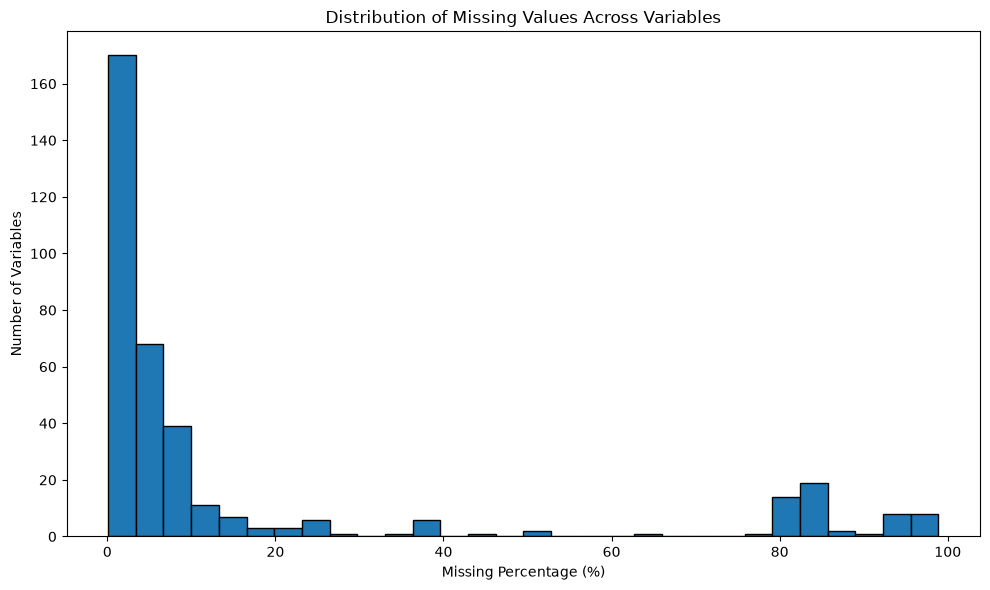

In [21]:
plt.figure(figsize=(10, 6))

plt.hist(
    missing_summary["Missing_percentage"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Missing Percentage (%)")
plt.ylabel("Number of Variables")
plt.title("Distribution of Missing Values Across Variables")

plt.tight_layout()
plt.show()

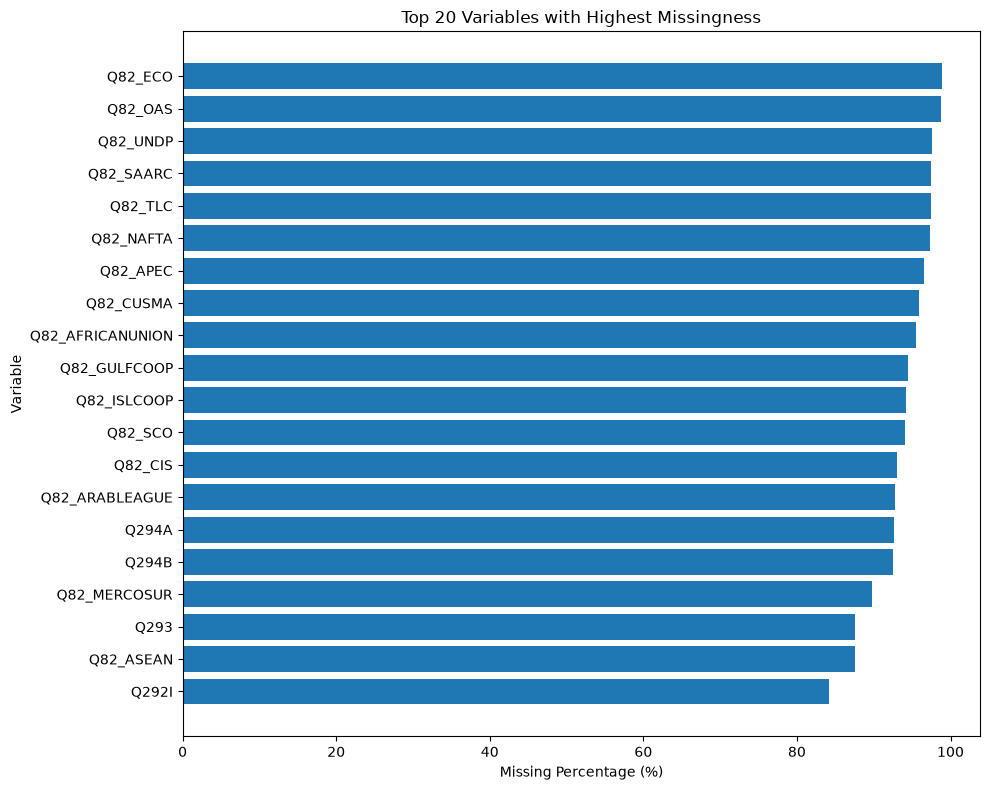

In [22]:
top_missing = missing_summary.head(20)

plt.figure(figsize=(10, 8))

plt.barh(
    top_missing.index[::-1],
    top_missing["Missing_percentage"].iloc[::-1]
)

plt.xlabel("Missing Percentage (%)")
plt.ylabel("Variable")
plt.title("Top 20 Variables with Highest Missingness")

plt.tight_layout()
plt.show()

In [23]:
country_sample_counts = (
    eda_data[country_variable]
    .value_counts()
    .sort_values(ascending=False)
)

print("Number of countries:", len(country_sample_counts))
print("\nCountry sample sizes:")
display(country_sample_counts.to_frame("Respondent_count"))

Number of countries: 66

Country sample sizes:


,Respondent_count
B_COUNTRY_ALPHA,
CAN,4018
IDN,3200
CHN,3036
GBR,2609
USA,2596
...,...
ARG,1003
CHL,1000
CYP,1000


In [24]:
country_sample_counts.to_csv(
    OUTPUT_DIR / "WVS_EDA_country_sample_counts.csv"
)

In [25]:
def country_missingness(variable):

    temp = eda_data[[country_variable, variable]].copy()

    temp["Is_missing"] = (
        temp[variable].isna()
        | temp[variable].isin(special_codes)
    )

    result = (
        temp.groupby(country_variable)
        .agg(
            Respondent_count=(variable, "size"),
            Missing_count=("Is_missing", "sum"),
            Missing_percentage=("Is_missing", "mean")
        )
        .reset_index()
    )

    result["Missing_percentage"] *= 100

    return result.sort_values(
        "Missing_percentage",
        ascending=False
    )

In [26]:
variables_to_check = ["Q82_ECO", "Q294A", "Q49", "Q57"]

for variable in variables_to_check:

    print(f"\n--- {variable} ---")

    display(country_missingness(variable).head(10))


--- Q82_ECO ---


,B_COUNTRY_ALPHA,Respondent_count,Missing_count,Missing_percentage
0,AND,1004,1004,100.0
1,ARG,1003,1003,100.0
2,ARM,1223,1223,100.0
3,AUS,1813,1813,100.0
4,BGD,1200,1200,100.0
5,BOL,2067,2067,100.0
6,BRA,1762,1762,100.0
7,CAN,4018,4018,100.0
8,CHL,1000,1000,100.0
9,CHN,3036,3036,100.0



--- Q294A ---


,B_COUNTRY_ALPHA,Respondent_count,Missing_count,Missing_percentage
0,AND,1004,1004,100.0
1,ARG,1003,1003,100.0
2,ARM,1223,1223,100.0
3,AUS,1813,1813,100.0
4,BGD,1200,1200,100.0
5,BOL,2067,2067,100.0
6,BRA,1762,1762,100.0
7,CAN,4018,4018,100.0
8,CHL,1000,1000,100.0
9,CHN,3036,3036,100.0



--- Q49 ---


,B_COUNTRY_ALPHA,Respondent_count,Missing_count,Missing_percentage
62,UZB,1250,106,8.480000
43,NLD,2145,82,3.822844
44,NZL,1057,32,3.027436
32,LBY,1196,29,2.424749
59,UKR,1289,25,1.939488
26,JPN,1353,23,1.699926
27,KAZ,1276,15,1.175549
52,SRB,1046,12,1.147228
8,CHL,1000,9,0.900000
3,AUS,1813,16,0.882515



--- Q57 ---


,B_COUNTRY_ALPHA,Respondent_count,Missing_count,Missing_percentage
43,NLD,2145,204,9.510490
33,MAC,1023,55,5.376344
26,JPN,1353,72,5.321508
1,ARG,1003,51,5.084746
54,THA,1500,75,5.000000
44,NZL,1057,52,4.919584
27,KAZ,1276,58,4.545455
11,CYP,1000,40,4.000000
62,UZB,1250,40,3.200000
13,DEU,1528,46,3.010471


In [27]:
def country_coverage_summary(variable):

    country_stats = country_missingness(variable)

    valid_countries = (
        country_stats["Missing_percentage"] < 100
    ).sum()

    countries_without_valid_responses = (
        country_stats["Missing_percentage"] == 100
    ).sum()

    return {
        "Variable": variable,
        "Total_countries": len(country_stats),
        "Countries_with_valid_responses": valid_countries,
        "Countries_without_valid_responses":
            countries_without_valid_responses,
        "Country_coverage_percentage":
            valid_countries / len(country_stats) * 100
    }

In [28]:
coverage_results = pd.DataFrame([
    country_coverage_summary(variable)
    for variable in ["Q82_ECO", "Q294A", "Q49", "Q57"]
])

display(coverage_results)

,Variable,Total_countries,Countries_with_valid_responses,Countries_without_valid_responses,Country_coverage_percentage
0,Q82_ECO,66,1,65,1.515152
1,Q294A,66,12,54,18.181818
2,Q49,66,66,0,100.000000
3,Q57,66,66,0,100.000000


In [29]:
for variable in ["Q82_ECO", "Q294A"]:

    print(f"\n--- Countries with valid responses: {variable} ---")

    country_stats = country_missingness(variable)

    display(
        country_stats[
            country_stats["Missing_percentage"] < 100
        ].sort_values("Missing_percentage")
    )


--- Countries with valid responses: Q82_ECO ---


,B_COUNTRY_ALPHA,Respondent_count,Missing_count,Missing_percentage
23,IRN,1499,426,28.418946



--- Countries with valid responses: Q294A ---


,B_COUNTRY_ALPHA,Respondent_count,Missing_count,Missing_percentage
65,ZWE,1215,590,48.559671
23,IRN,1499,738,49.232822
63,VEN,1190,590,49.579832
47,PHL,1200,600,50.000000
64,VNM,1200,600,50.000000
37,MMR,1200,600,50.000000
29,KGZ,1200,607,50.583333
41,NIC,1200,610,50.833333
32,LBY,1196,627,52.424749
28,KEN,1266,680,53.712480


In [30]:
coverage_results.to_csv(
    OUTPUT_DIR / "WVS_EDA_country_coverage_summary.csv",
    index=False
)

In [31]:
for variable in ["Q82_ECO", "Q294A", "Q49", "Q57"]:

    country_stats = country_missingness(variable)

    country_stats.to_csv(
        OUTPUT_DIR / f"WVS_EDA_{variable}_country_missingness.csv",
        index=False
    )

In [32]:
coverage_analysis = missing_summary.copy()

coverage_analysis["Coverage_group"] = pd.cut(
    coverage_analysis["Country_coverage_percentage"],
    bins=[-0.01, 50, 80, 99.99, 100],
    labels=[
        "Very low coverage",
        "Low coverage",
        "High coverage",
        "Full coverage"
    ]
)

print(
    coverage_analysis["Coverage_group"].value_counts(
        sort=False
    )
)

Coverage_group
Very low coverage     53
Low coverage           5
High coverage        118
Full coverage        196
Name: count, dtype: int64


In [33]:
display(
    coverage_analysis[
        [
            "Missing_percentage",
            "Valid_response_count",
            "Countries_with_valid_responses",
            "Country_coverage_percentage",
            "Coverage_group"
        ]
    ].sort_values(
        "Country_coverage_percentage"
    ).head(30)
)

,Missing_percentage,Valid_response_count,Countries_with_valid_responses,Country_coverage_percentage,Coverage_group
Q82_ECO,98.896318,1073,1,1.515152,Very low coverage
Q82_OAS,98.759515,1206,1,1.515152,Very low coverage
Q82_NAFTA,97.394569,2533,1,1.515152,Very low coverage
Q82_CUSMA,95.867106,4018,1,1.515152,Very low coverage
Q82_SAARC,97.509772,2421,2,3.030303,Very low coverage
Q82_TLC,97.458342,2471,2,3.030303,Very low coverage
Q82_APEC,96.527463,3376,3,4.545455,Very low coverage
Q82_UNDP,97.633203,2301,3,4.545455,Very low coverage
Q82_AFRICANUNION,95.556470,4320,4,6.060606,Very low coverage
Q82_SCO,94.061921,5773,5,7.575758,Very low coverage


In [34]:
coverage_analysis.to_csv(
    OUTPUT_DIR / "WVS_EDA_variable_coverage_analysis.csv"
)

In [35]:
coverage_analysis = missing_summary.copy()

coverage_analysis["Coverage_group"] = pd.cut(
    coverage_analysis["Country_coverage_percentage"],
    bins=[-0.01, 50, 80, 99.99, 100],
    labels=[
        "Very low coverage",
        "Low coverage",
        "High coverage",
        "Full coverage"
    ]
)

print("Coverage group summary:")
print(
    coverage_analysis["Coverage_group"]
    .value_counts(sort=False)
)

Coverage group summary:
Coverage_group
Very low coverage     53
Low coverage           5
High coverage        118
Full coverage        196
Name: count, dtype: int64


In [36]:
display(
    coverage_analysis[
        [
            "Missing_percentage",
            "Valid_response_count",
            "Countries_with_valid_responses",
            "Country_coverage_percentage",
            "Coverage_group"
        ]
    ]
    .sort_values(
        ["Country_coverage_percentage", "Missing_percentage"]
    )
    .head(30)
)

,Missing_percentage,Valid_response_count,Countries_with_valid_responses,Country_coverage_percentage,Coverage_group
Q82_CUSMA,95.867106,4018,1,1.515152,Very low coverage
Q82_NAFTA,97.394569,2533,1,1.515152,Very low coverage
Q82_OAS,98.759515,1206,1,1.515152,Very low coverage
Q82_ECO,98.896318,1073,1,1.515152,Very low coverage
Q82_TLC,97.458342,2471,2,3.030303,Very low coverage
Q82_SAARC,97.509772,2421,2,3.030303,Very low coverage
Q82_APEC,96.527463,3376,3,4.545455,Very low coverage
Q82_UNDP,97.633203,2301,3,4.545455,Very low coverage
Q82_AFRICANUNION,95.556470,4320,4,6.060606,Very low coverage
Q82_SCO,94.061921,5773,5,7.575758,Very low coverage


In [37]:
coverage_group_summary = (
    coverage_analysis
    .groupby("Coverage_group", observed=False)
    .agg(
        Variable_count=("Country_coverage_percentage", "size"),
        Average_missing_percentage=("Missing_percentage", "mean"),
        Average_country_coverage=("Country_coverage_percentage", "mean")
    )
    .reset_index()
)

display(coverage_group_summary)

,Coverage_group,Variable_count,Average_missing_percentage,Average_country_coverage
0,Very low coverage,53,86.951672,16.723842
1,Low coverage,5,47.640403,61.212121
2,High coverage,118,10.347909,96.764253
3,Full coverage,196,2.324887,100.000000


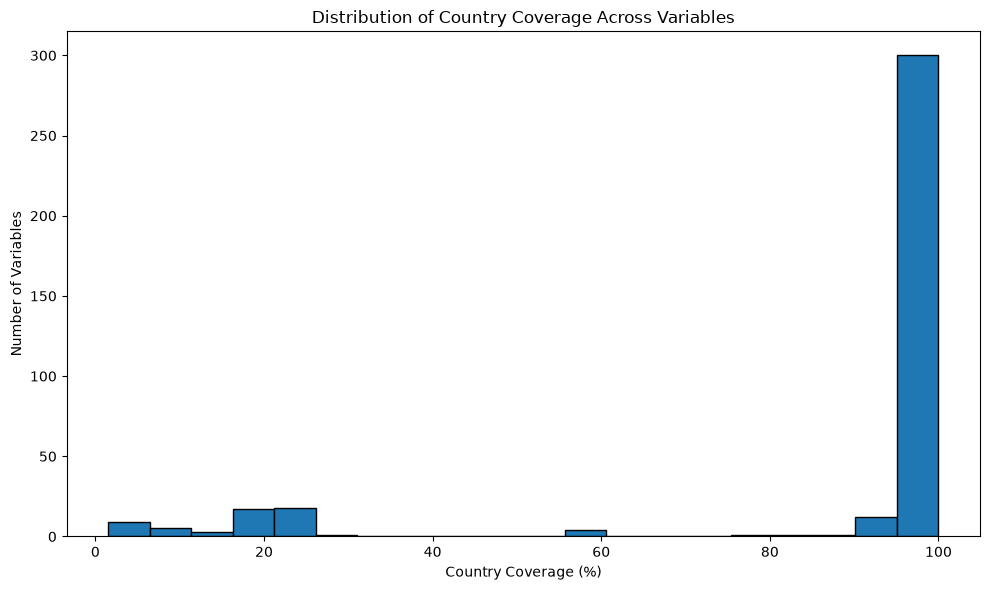

In [38]:
plt.figure(figsize=(10, 6))

plt.hist(
    coverage_analysis["Country_coverage_percentage"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Country Coverage (%)")
plt.ylabel("Number of Variables")
plt.title("Distribution of Country Coverage Across Variables")

plt.tight_layout()
plt.show()

In [39]:
coverage_analysis.to_csv(
    OUTPUT_DIR / "WVS_EDA_variable_coverage_analysis.csv",
    index=True
)

coverage_group_summary.to_csv(
    OUTPUT_DIR / "WVS_EDA_coverage_group_summary.csv",
    index=False
)

print("Coverage analysis files saved.")

Coverage analysis files saved.


### Country Coverage Analysis — Key Findings

The country coverage analysis examined all 372 variables in the master variable dictionary across 66 countries and regions.

The results show:

- 196 variables have valid responses in all 66 countries.
- 118 variables have high but incomplete country coverage.
- 5 variables have low country coverage.
- 53 variables have very low country coverage.

Variables with very low coverage are primarily associated with country-specific institutional confidence and limited-country political trust modules, including Q82_*, Q292, Q293 and Q294.

These findings indicate that missingness is partly related to differences in survey coverage across countries.

Variables with limited country coverage will be retained for exploratory purposes but will not automatically be included in the main cross-country analysis.

## 5. Univariate Analysis

### 5.1 Life Satisfaction (Q49)

Q49 measures respondents' overall life satisfaction on a scale from 1 to 10.

This analysis examines the distribution of life satisfaction across the full WVS Wave 7 sample, including its central tendency, variability and response patterns.

Special missing-value codes will be excluded from the descriptive analysis.

In [40]:
# Identify valid Q49 responses
q49_valid = eda_data.loc[
    eda_data["Q49"].notna()
    & ~eda_data["Q49"].isin(special_codes),
    "Q49"
]

print("Total respondents:", len(eda_data))
print("Valid Q49 responses:", len(q49_valid))
print("Missing Q49 responses:", len(eda_data) - len(q49_valid))
print("Valid response rate:", round(len(q49_valid) / len(eda_data) * 100, 2), "%")

Total respondents: 97220
Valid Q49 responses: 96700
Missing Q49 responses: 520
Valid response rate: 99.47 %


In [41]:
q49_descriptive = q49_valid.describe()

display(q49_descriptive)

count    96700.000000
mean         7.062130
std          2.239034
min          1.000000
25%          6.000000
50%          7.000000
75%          9.000000
max         10.000000
Name: Q49, dtype: float64

In [42]:
print("Mean:", round(q49_valid.mean(), 3))
print("Median:", q49_valid.median())
print("Mode:", q49_valid.mode().tolist())
print("Standard deviation:", round(q49_valid.std(), 3))
print("Minimum:", q49_valid.min())
print("Maximum:", q49_valid.max())

Mean: 7.062
Median: 7.0
Mode: [8]
Standard deviation: 2.239
Minimum: 1
Maximum: 10


In [43]:
q49_distribution = (
    q49_valid
    .value_counts()
    .sort_index()
    .rename_axis("Life_Satisfaction")
    .reset_index(name="Respondent_count")
)

q49_distribution["Percentage"] = (
    q49_distribution["Respondent_count"]
    / len(q49_valid) * 100
)

display(q49_distribution)

,Life_Satisfaction,Respondent_count,Percentage
0,1,2632,2.721820
1,2,1421,1.469493
2,3,3140,3.247156
3,4,4476,4.628749
4,5,11530,11.923475
5,6,10986,11.360910
6,7,16377,16.935884
7,8,19689,20.360910
8,9,10097,10.441572
9,10,16352,16.910031


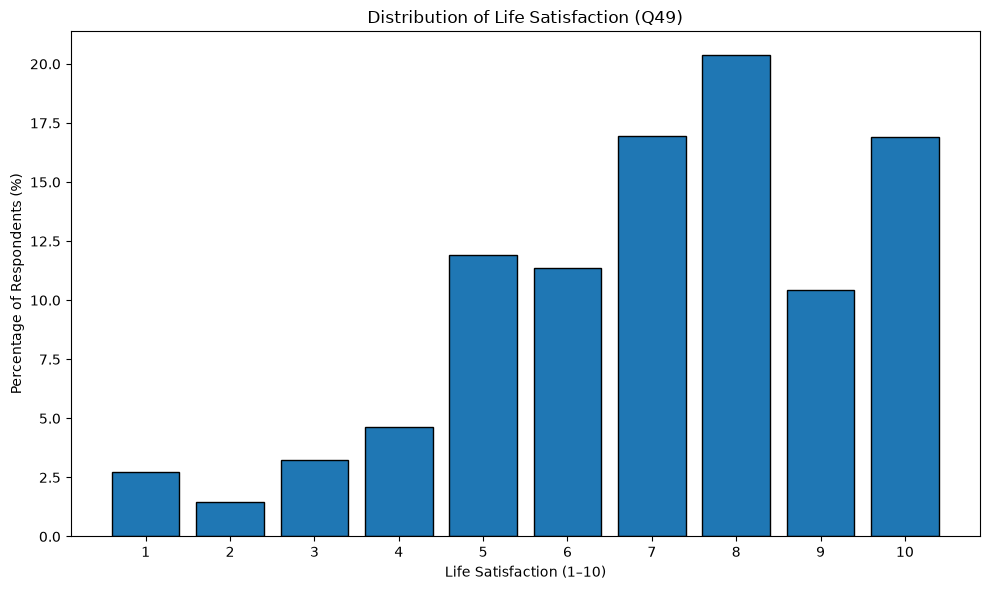

In [44]:
plt.figure(figsize=(10, 6))

plt.bar(
    q49_distribution["Life_Satisfaction"],
    q49_distribution["Percentage"],
    edgecolor="black"
)

plt.xticks(range(1, 11))
plt.xlabel("Life Satisfaction (1–10)")
plt.ylabel("Percentage of Respondents (%)")
plt.title("Distribution of Life Satisfaction (Q49)")

plt.tight_layout()
plt.show()

In [45]:
q49_distribution.to_csv(
    OUTPUT_DIR / "WVS_EDA_Q49_distribution.csv",
    index=False
)

q49_descriptive.to_csv(
    OUTPUT_DIR / "WVS_EDA_Q49_descriptive_statistics.csv"
)

print("Q49 analysis results saved.")

Q49 analysis results saved.


### Key Findings: Life Satisfaction (Q49)

The analysis of 96,700 valid responses shows an average life satisfaction score of 7.062 on the 1–10 scale. The median is 7, and the most frequent response is 8.

The distribution is concentrated in the higher range:

- 64.65% of respondents selected scores between 7 and 10.
- 12.07% selected scores between 1 and 4.
- 20.36% selected 8, making it the most common response.
- 16.91% selected the maximum score of 10.

The standard deviation is 2.239, indicating meaningful variation in life satisfaction across respondents.

Overall, the results suggest that life satisfaction is relatively high in the pooled WVS Wave 7 sample, while substantial differences between respondents remain to be explored.

These descriptive findings provide the foundation for examining the economic, social, demographic and personal factors associated with life satisfaction.

### 5.2 Life Satisfaction Across Countries

This analysis examines differences in life satisfaction across the 66 countries and regions included in WVS Wave 7.

For each country, the following statistics are calculated:

- Mean life satisfaction
- Median life satisfaction
- Standard deviation
- Number of valid responses

The purpose is to explore cross-country differences and understand how the pooled sample distribution relates to country-level patterns.

In [46]:
country_q49_data = eda_data[
    [country_variable, "Q49"]
].copy()

country_q49_data = country_q49_data[
    country_q49_data["Q49"].notna()
    & ~country_q49_data["Q49"].isin(special_codes)
]

In [47]:
country_q49_summary = (
    country_q49_data
    .groupby(country_variable)["Q49"]
    .agg(
        Mean="mean",
        Median="median",
        Std="std",
        Valid_responses="count"
    )
    .reset_index()
    .sort_values("Mean", ascending=False)
)

country_q49_summary["Mean"] = (
    country_q49_summary["Mean"].round(3)
)

country_q49_summary["Std"] = (
    country_q49_summary["Std"].round(3)
)

display(country_q49_summary)

,B_COUNTRY_ALPHA,Mean,Median,Std,Valid_responses
48,PRI,8.405,9.0,2.132,1122
29,KGZ,8.383,10.0,2.290,1198
10,COL,8.188,9.0,2.156,1520
36,MEX,8.137,9.0,2.064,1740
60,URY,8.128,8.0,1.840,999
...,...,...,...,...,...
16,ETH,5.779,6.0,2.836,1229
40,NGA,5.617,6.0,2.701,1236
56,TUN,5.522,5.0,2.493,1207
65,ZWE,4.951,5.0,3.324,1214


In [48]:
top_10_countries = country_q49_summary.head(10)

display(top_10_countries)

,B_COUNTRY_ALPHA,Mean,Median,Std,Valid_responses
48,PRI,8.405,9.0,2.132,1122
29,KGZ,8.383,10.0,2.290,1198
10,COL,8.188,9.0,2.156,1520
36,MEX,8.137,9.0,2.064,1740
60,URY,8.128,8.0,1.840,999
64,VNM,8.026,8.0,1.541,1200
55,TJK,7.949,8.0,1.878,1200
41,NIC,7.943,8.0,2.297,1200
32,LBY,7.929,8.0,2.217,1167
14,ECU,7.785,8.0,2.345,1198


In [49]:
bottom_10_countries = (
    country_q49_summary
    .sort_values("Mean", ascending=True)
    .head(10)
)

display(bottom_10_countries)

,B_COUNTRY_ALPHA,Mean,Median,Std,Valid_responses
24,IRQ,4.465,4.0,1.904,1200
65,ZWE,4.951,5.0,3.324,1214
56,TUN,5.522,5.0,2.493,1207
40,NGA,5.617,6.0,2.701,1236
16,ETH,5.779,6.0,2.836,1229
15,EGY,5.868,6.0,2.312,1197
28,KEN,5.875,6.0,2.675,1256
59,UKR,6.097,6.0,2.119,1264
18,GRC,6.182,7.0,2.066,1200
23,IRN,6.201,6.0,2.624,1498


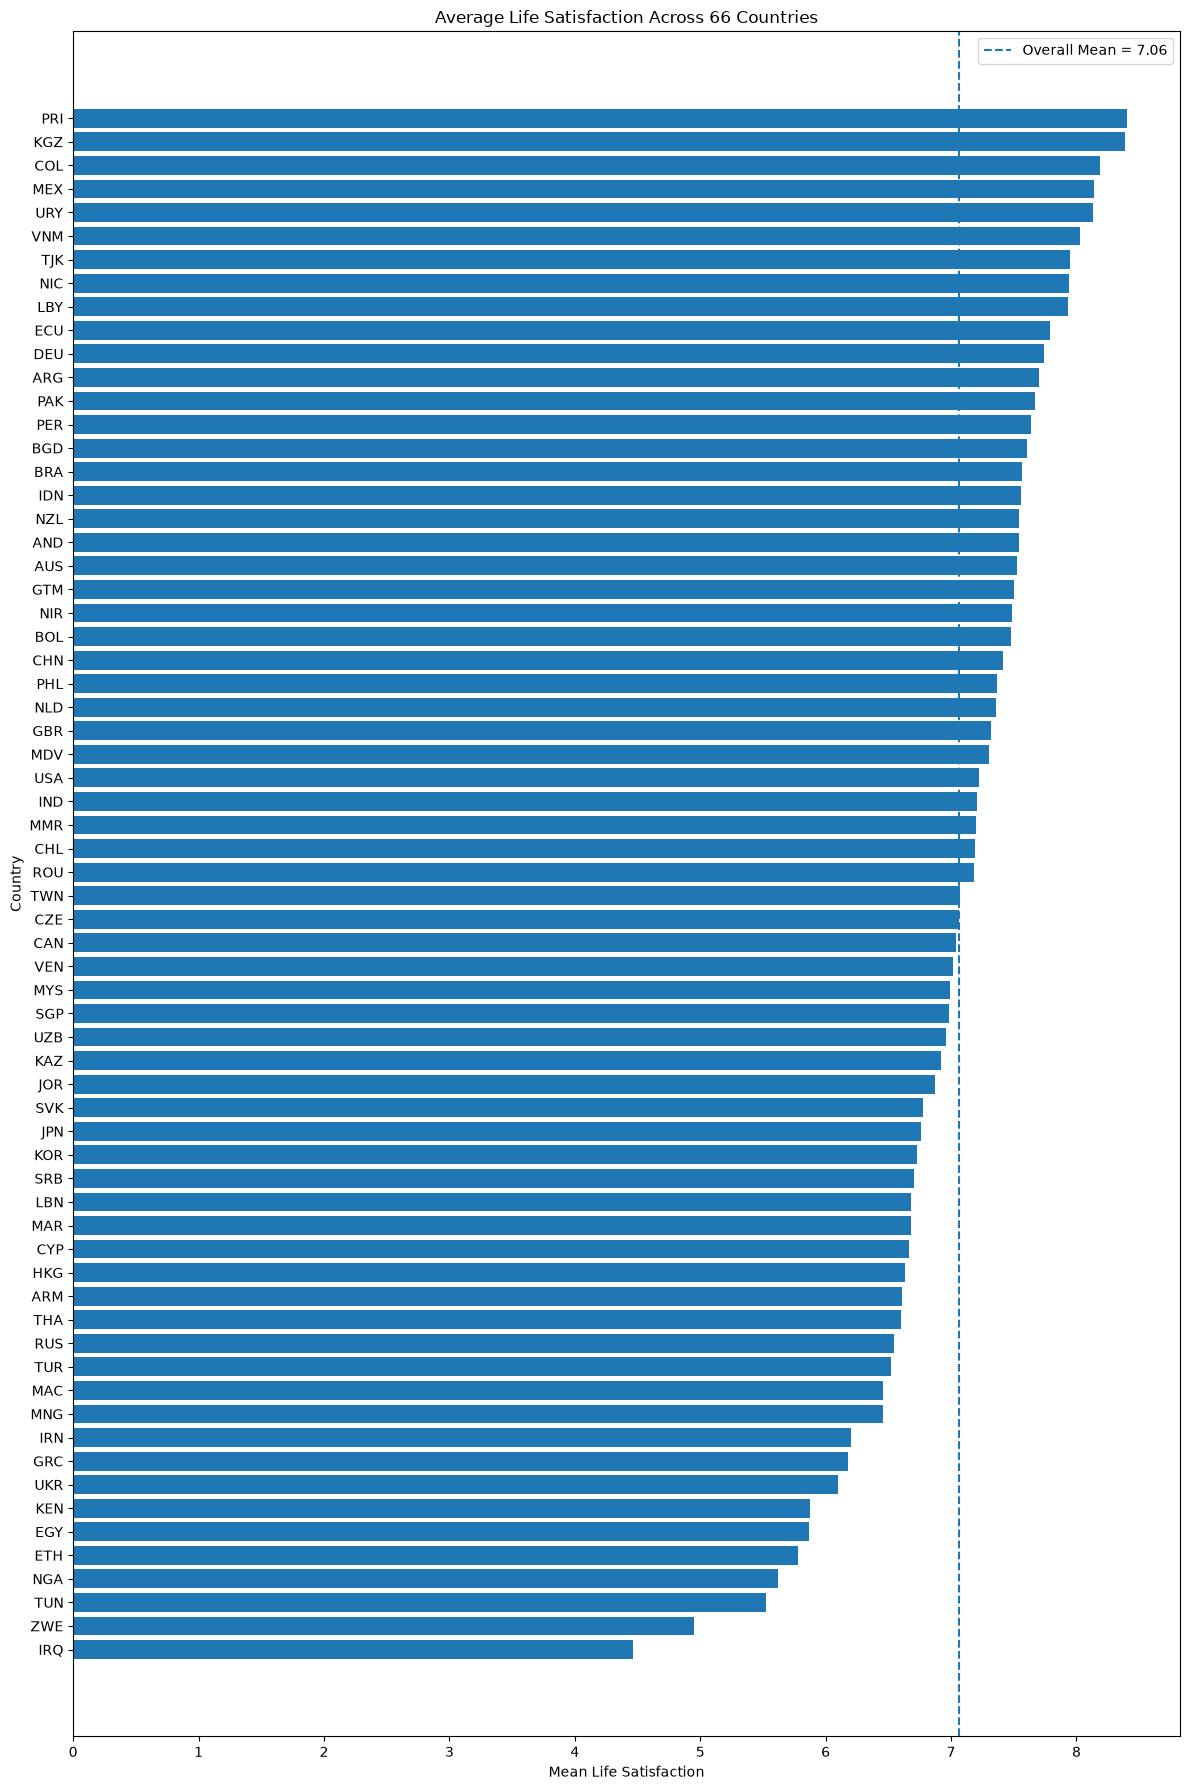

In [50]:
country_q49_sorted = country_q49_summary.sort_values(
    "Mean",
    ascending=True
)

plt.figure(figsize=(12, 18))

plt.barh(
    country_q49_sorted[country_variable],
    country_q49_sorted["Mean"]
)

plt.axvline(
    q49_valid.mean(),
    linestyle="--",
    label=f"Overall Mean = {q49_valid.mean():.2f}"
)

plt.xlabel("Mean Life Satisfaction")
plt.ylabel("Country")
plt.title("Average Life Satisfaction Across 66 Countries")

plt.legend()
plt.tight_layout()
plt.show()

In [51]:
print(
    "Highest country mean:",
    country_q49_summary["Mean"].max()
)

print(
    "Lowest country mean:",
    country_q49_summary["Mean"].min()
)

print(
    "Difference between highest and lowest:",
    round(
        country_q49_summary["Mean"].max()
        - country_q49_summary["Mean"].min(),
        3
    )
)

print(
    "Average of country means:",
    round(country_q49_summary["Mean"].mean(), 3)
)

Highest country mean: 8.405
Lowest country mean: 4.465
Difference between highest and lowest: 3.94
Average of country means: 7.037


In [52]:
country_q49_summary.to_csv(
    OUTPUT_DIR / "WVS_EDA_Q49_country_summary.csv",
    index=False
)

print("Country-level Q49 analysis saved.")

Country-level Q49 analysis saved.


### Key Findings: Life Satisfaction Across Countries

The country-level analysis reveals substantial differences in average life satisfaction across the 66 countries and regions included in WVS Wave 7.

The highest country-level mean is 8.405, while the lowest is 4.465, resulting in a difference of 3.940 points on the 1–10 scale.

The highest average scores are observed in PRI, KGZ, COL, MEX and URY. The lowest are observed in IRQ, ZWE, TUN, NGA and ETH.

The pooled respondent-level mean is 7.062, compared with an unweighted average of country means of 7.037. The difference reflects the fact that country sample sizes vary.

These descriptive findings suggest that life satisfaction varies substantially both across respondents and across countries.

However, country-level differences alone do not explain why these differences occur. Further analysis of economic, demographic, social and personal factors is required.

### 5.3 Within-Country and Between-Country Variation

This analysis decomposes the total variation in life satisfaction into:

- Within-country variation: differences in life satisfaction among respondents within the same country.
- Between-country variation: differences in average life satisfaction across countries.

The purpose is to examine how much of the observed variation is associated with individual differences within countries versus differences between country averages.

This is a descriptive variance decomposition and does not establish causal relationships.

In [53]:
variance_data = eda_data[
    [country_variable, "Q49"]
].copy()

variance_data = variance_data[
    variance_data["Q49"].notna()
    & ~variance_data["Q49"].isin(special_codes)
]

print("Valid observations:", len(variance_data))
print("Number of countries:", variance_data[country_variable].nunique())

Valid observations: 96700
Number of countries: 66


In [54]:
grand_mean = variance_data["Q49"].mean()

SS_total = (
    (variance_data["Q49"] - grand_mean) ** 2
).sum()

print("Grand mean:", round(grand_mean, 4))
print("Total sum of squares:", round(SS_total, 2))

Grand mean: 7.0621
Total sum of squares: 484778.72


In [55]:
country_means = (
    variance_data
    .groupby(country_variable)["Q49"]
    .transform("mean")
)

In [56]:
SS_within = (
    (variance_data["Q49"] - country_means) ** 2
).sum()

print("Within-country sum of squares:", round(SS_within, 2))

Within-country sum of squares: 432766.4


In [57]:
country_stats = (
    variance_data
    .groupby(country_variable)["Q49"]
    .agg(["mean", "count"])
)

SS_between = (
    country_stats["count"]
    * (country_stats["mean"] - grand_mean) ** 2
).sum()

print("Between-country sum of squares:", round(SS_between, 2))

Between-country sum of squares: 52012.33


In [58]:
print("Total SS:", round(SS_total, 4))
print("Within SS + Between SS:", round(SS_within + SS_between, 4))

print(
    "Decomposition check:",
    np.isclose(SS_total, SS_within + SS_between)
)

Total SS: 484778.7212
Within SS + Between SS: 484778.7212
Decomposition check: True


In [59]:
within_percentage = SS_within / SS_total * 100
between_percentage = SS_between / SS_total * 100

variance_decomposition = pd.DataFrame({
    "Variation_source": [
        "Within-country",
        "Between-country"
    ],
    "Sum_of_squares": [
        SS_within,
        SS_between
    ],
    "Percentage_of_total_variation": [
        within_percentage,
        between_percentage
    ]
})

display(variance_decomposition)

,Variation_source,Sum_of_squares,Percentage_of_total_variation
0,Within-country,432766.395335,89.270914
1,Between-country,52012.325823,10.729086


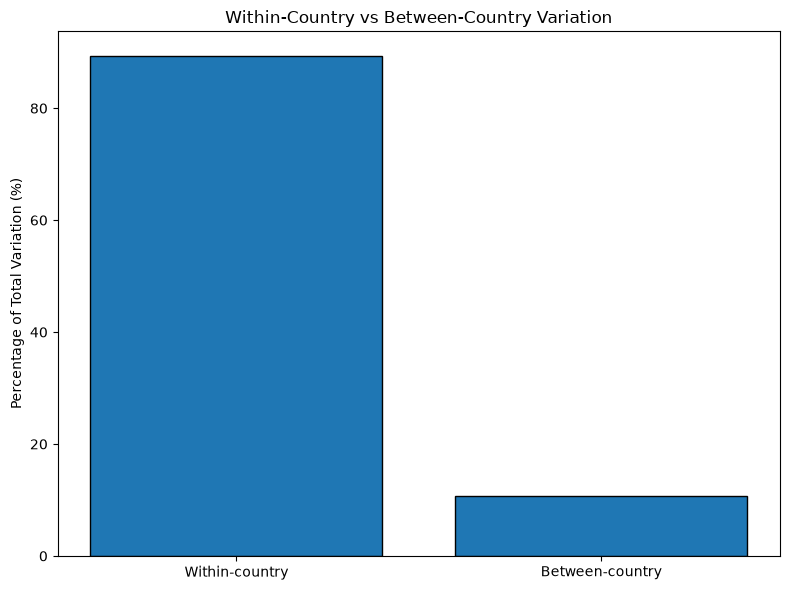

In [60]:
plt.figure(figsize=(8, 6))

plt.bar(
    variance_decomposition["Variation_source"],
    variance_decomposition["Percentage_of_total_variation"],
    edgecolor="black"
)

plt.ylabel("Percentage of Total Variation (%)")
plt.title("Within-Country vs Between-Country Variation")

plt.tight_layout()
plt.show()

In [61]:
variance_decomposition.to_csv(
    OUTPUT_DIR / "WVS_EDA_Q49_variance_decomposition.csv",
    index=False
)

print("Variance decomposition saved.")

Variance decomposition saved.


### Key Findings: Within-Country and Between-Country Variation

The variance decomposition of life satisfaction across 96,700 respondents and 66 countries shows that:

- Within-country variation accounts for 89.27% of total variation.
- Between-country variation accounts for 10.73% of total variation.

These findings indicate that most observed variation in life satisfaction occurs among individuals within the same country, while differences between country averages account for a smaller proportion.

This highlights the importance of examining individual-level economic, demographic, social and personal factors rather than focusing exclusively on country-level differences.

The results are descriptive and do not establish causal relationships or identify the contribution of specific explanatory variables.

### 5.4 Economic Factors

This section examines the distribution of economic variables across three feature groups:

- Economic Security (Q50–Q56)
- Economic Values (Q106–Q111)
- Household Economic Position (Q285–Q288 and Q288R)

The analysis explores respondents' economic circumstances, perceptions of economic conditions, household economic position and attitudes towards economic issues.

The purpose is to identify potentially relevant economic predictors of life satisfaction.

In [62]:
economic_variables = master_dictionary.loc[
    master_dictionary["Category"] == "Economic",
    "Variable"
].tolist()

economic_dictionary = master_dictionary[
    master_dictionary["Category"] == "Economic"
].copy()

print("Number of economic variables:", len(economic_variables))

display(
    economic_dictionary[
        [
            "Variable",
            "Feature_group",
            "Measurement_type",
            "Variable_role",
            "Model_status",
            "Missing percentage (NaN)",
            "Countries_with_valid_responses",
            "Country_coverage_percentage"
        ]
    ]
)

Number of economic variables: 18


,Variable,Feature_group,Measurement_type,Variable_role,Model_status,Missing percentage (NaN),Countries_with_valid_responses,Country_coverage_percentage
48,Q50,Economic Security,Ordinal,Predictor candidate,Candidate,0.0,66.0,100.0
49,Q51,Economic Security,Ordinal,Predictor candidate,Candidate,0.0,66.0,100.0
50,Q52,Economic Security,Ordinal,Predictor candidate,Candidate,0.0,66.0,100.0
51,Q53,Economic Security,Ordinal,Predictor candidate,Candidate,0.0,66.0,100.0
52,Q54,Economic Security,Ordinal,Predictor candidate,Candidate,0.0,66.0,100.0
53,Q55,Economic Security,Ordinal,Predictor candidate,Candidate,0.0,66.0,100.0
54,Q56,Economic Security,Nominal,Predictor candidate,Candidate,0.0,66.0,100.0
132,Q106,Economic Values,Ordinal,Predictor candidate,Candidate,0.0,NaN,NaN
133,Q107,Economic Values,Ordinal,Predictor candidate,Candidate,0.0,NaN,NaN
134,Q108,Economic Values,Ordinal,Predictor candidate,Candidate,0.0,NaN,NaN


In [63]:
economic_summary = missing_summary.loc[
    economic_variables,
    [
        "NaN_count",
        "Special_code_count",
        "Total_missing_count",
        "Missing_percentage",
        "Valid_response_count",
        "Countries_with_valid_responses",
        "Country_coverage_percentage"
    ]
].copy()

display(
    economic_summary.sort_values(
        "Missing_percentage",
        ascending=False
    )
)

,NaN_count,Special_code_count,Total_missing_count,Missing_percentage,Valid_response_count,Countries_with_valid_responses,Country_coverage_percentage
Q287,0,5547,5547,5.705616,91673,64,96.969697
Q111,0,4651,4651,4.783995,92569,66,100.000000
Q107,0,3444,3444,3.542481,93776,66,100.000000
Q288,0,2961,2961,3.045670,94259,66,100.000000
Q288R,0,2961,2961,3.045670,94259,66,100.000000
Q286,0,2940,2940,3.024069,94280,66,100.000000
Q285,0,2707,2707,2.784407,94513,66,100.000000
Q56,0,1760,1760,1.810327,95460,66,100.000000
Q109,0,1662,1662,1.709525,95558,66,100.000000
Q110,0,1441,1441,1.482205,95779,66,100.000000


In [64]:
print(
    economic_dictionary["Measurement_type"]
    .value_counts()
)

Measurement_type
Ordinal    15
Nominal     2
Binary      1
Name: count, dtype: int64


In [65]:
economic_security = [
    f"Q{i}" for i in range(50, 57)
]

economic_values = [
    f"Q{i}" for i in range(106, 112)
]

household_economic = [
    "Q285", "Q286", "Q287", "Q288", "Q288R"
]

print("Economic Security:", len(economic_security))
print("Economic Values:", len(economic_values))
print("Household Economic Position:", len(household_economic))

Economic Security: 7
Economic Values: 6
Household Economic Position: 5


In [66]:
ordinal_economic_variables = economic_dictionary.loc[
    economic_dictionary["Measurement_type"] == "Ordinal",
    "Variable"
].tolist()

print("Ordinal economic variables:", len(ordinal_economic_variables))

Ordinal economic variables: 15


In [67]:
def get_response_distribution(data, variable):

    valid_data = data.loc[
        data[variable].notna()
        & ~data[variable].isin(special_codes),
        variable
    ]

    result = (
        valid_data
        .value_counts()
        .sort_index()
        .rename_axis("Response")
        .reset_index(name="Count")
    )

    result["Percentage"] = (
        result["Count"] / len(valid_data) * 100
    )

    return result

In [68]:
display(get_response_distribution(eda_data, "Q50"))

,Response,Count,Percentage
0,1,5331,5.518919
1,2,3109,3.218593
2,3,5568,5.764274
3,4,7100,7.350277
4,5,15356,15.897303
5,6,13034,13.493452
6,7,15518,16.065014
7,8,14833,15.355867
8,9,6630,6.863709
9,10,10116,10.472592


In [69]:
economic_ordinal_distributions = {}

for variable in ordinal_economic_variables:

    economic_ordinal_distributions[variable] = (
        get_response_distribution(eda_data, variable)
    )

    print(f"\n--- {variable} ---")

    display(economic_ordinal_distributions[variable])


--- Q50 ---


,Response,Count,Percentage
0,1,5331,5.518919
1,2,3109,3.218593
2,3,5568,5.764274
3,4,7100,7.350277
4,5,15356,15.897303
5,6,13034,13.493452
6,7,15518,16.065014
7,8,14833,15.355867
8,9,6630,6.863709
9,10,10116,10.472592



--- Q51 ---


,Response,Count,Percentage
0,1,3958,4.092902
1,2,10933,11.305634
2,3,15041,15.553648
3,4,66772,69.047816



--- Q52 ---


,Response,Count,Percentage
0,1,4344,4.495359
1,2,11575,11.978310
2,3,16832,17.418480
3,4,63882,66.107851


... (20 outputs left out)


--- Q288 ---


,Response,Count,Percentage
0,1,7277,7.720218
1,2,5502,5.837108
2,3,10587,11.231819
3,4,13148,13.948801
4,5,22535,23.907531
5,6,14527,15.411791
6,7,11008,11.678460
7,8,5801,6.154319
8,9,1828,1.939337
9,10,2046,2.170615



--- Q288R ---


,Response,Count,Percentage
0,1,23366,24.789145
1,2,61218,64.946583
2,3,9675,10.264272


In [70]:
for variable in ["Q111", "Q285"]:

    print(f"\n--- {variable} ---")

    display(get_response_distribution(eda_data, variable))


--- Q111 ---


,Response,Count,Percentage
0,1,52883,57.128196
1,2,36829,39.785457
2,3,2857,3.086346



--- Q285 ---


,Response,Count,Percentage
0,1,44035,46.591474
1,2,50478,53.408526


In [71]:
def plot_variable_distributions(data, variables, title):

    n = len(variables)

    fig, axes = plt.subplots(
        nrows=n,
        ncols=1,
        figsize=(9, 3 * n)
    )

    if n == 1:
        axes = [axes]

    for ax, variable in zip(axes, variables):

        distribution = get_response_distribution(
            data, variable
        )

        ax.bar(
            distribution["Response"],
            distribution["Percentage"],
            edgecolor="black"
        )

        ax.set_title(variable)
        ax.set_xlabel("Response category")
        ax.set_ylabel("Percentage (%)")

    fig.suptitle(title, fontsize=15, y=1.002)
    plt.tight_layout()
    plt.show()

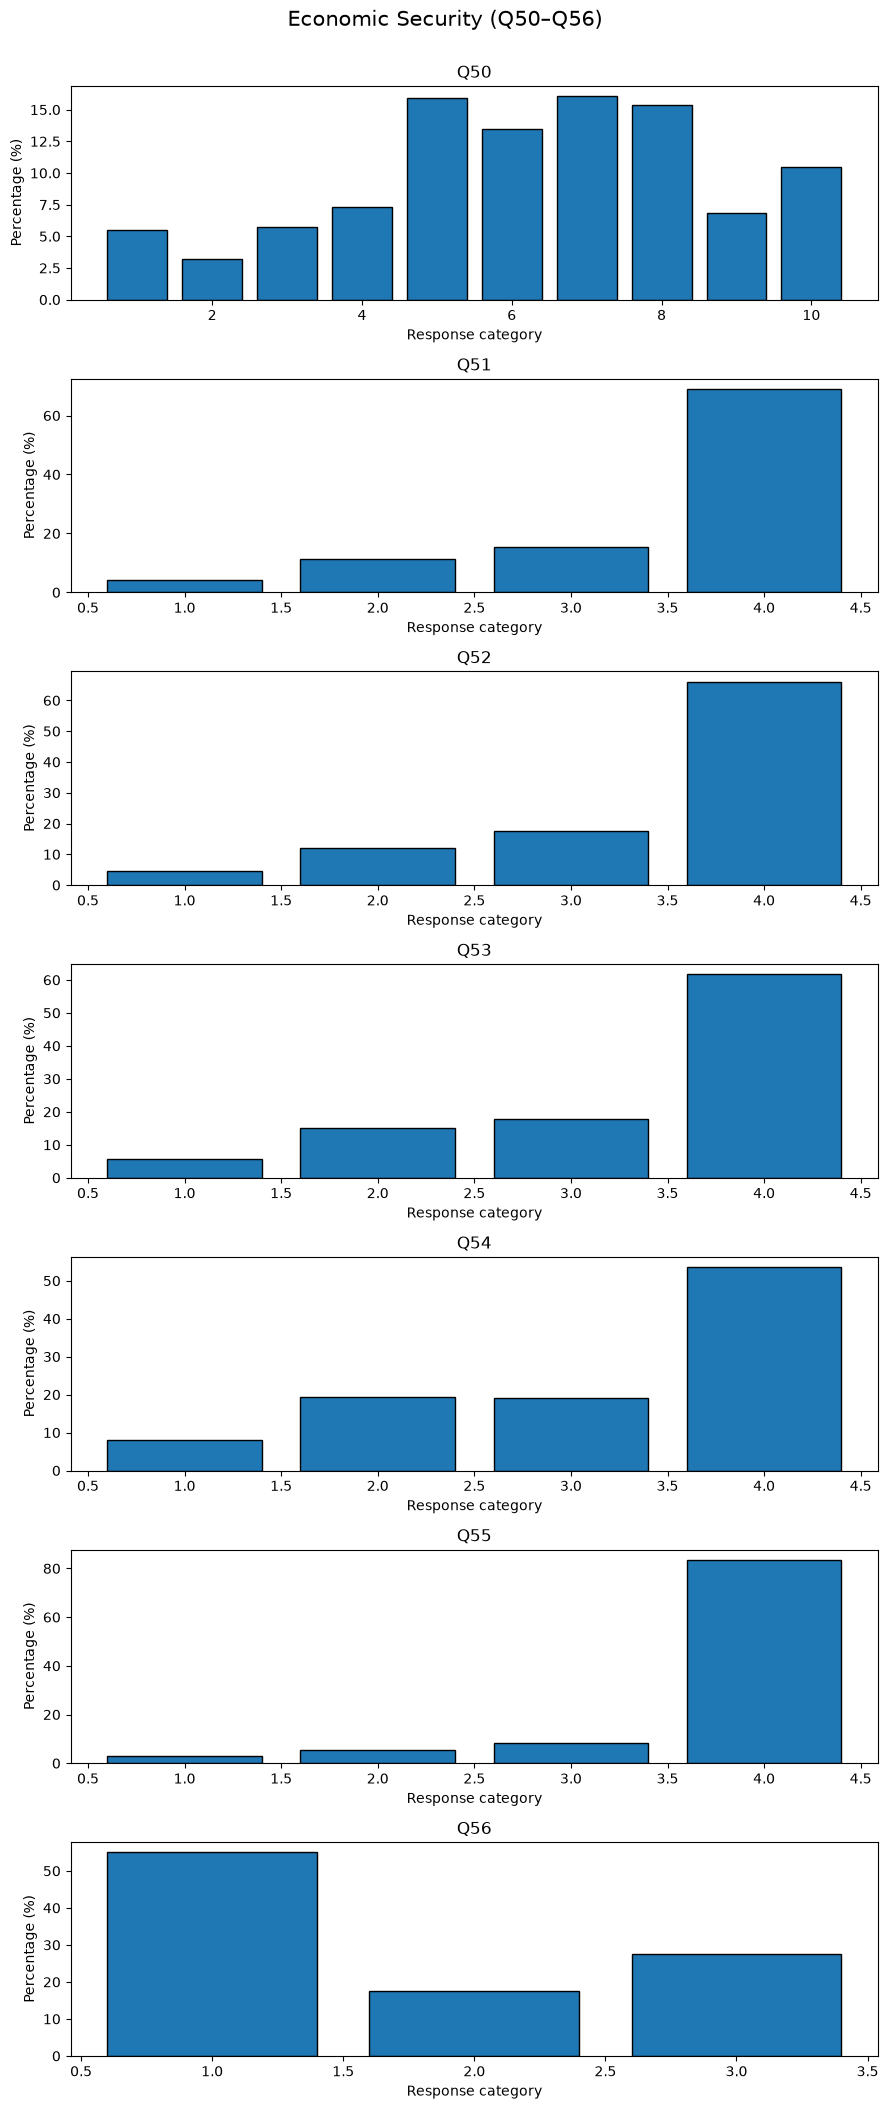

In [72]:
plot_variable_distributions(
    eda_data,
    economic_security,
    "Economic Security (Q50–Q56)"
)

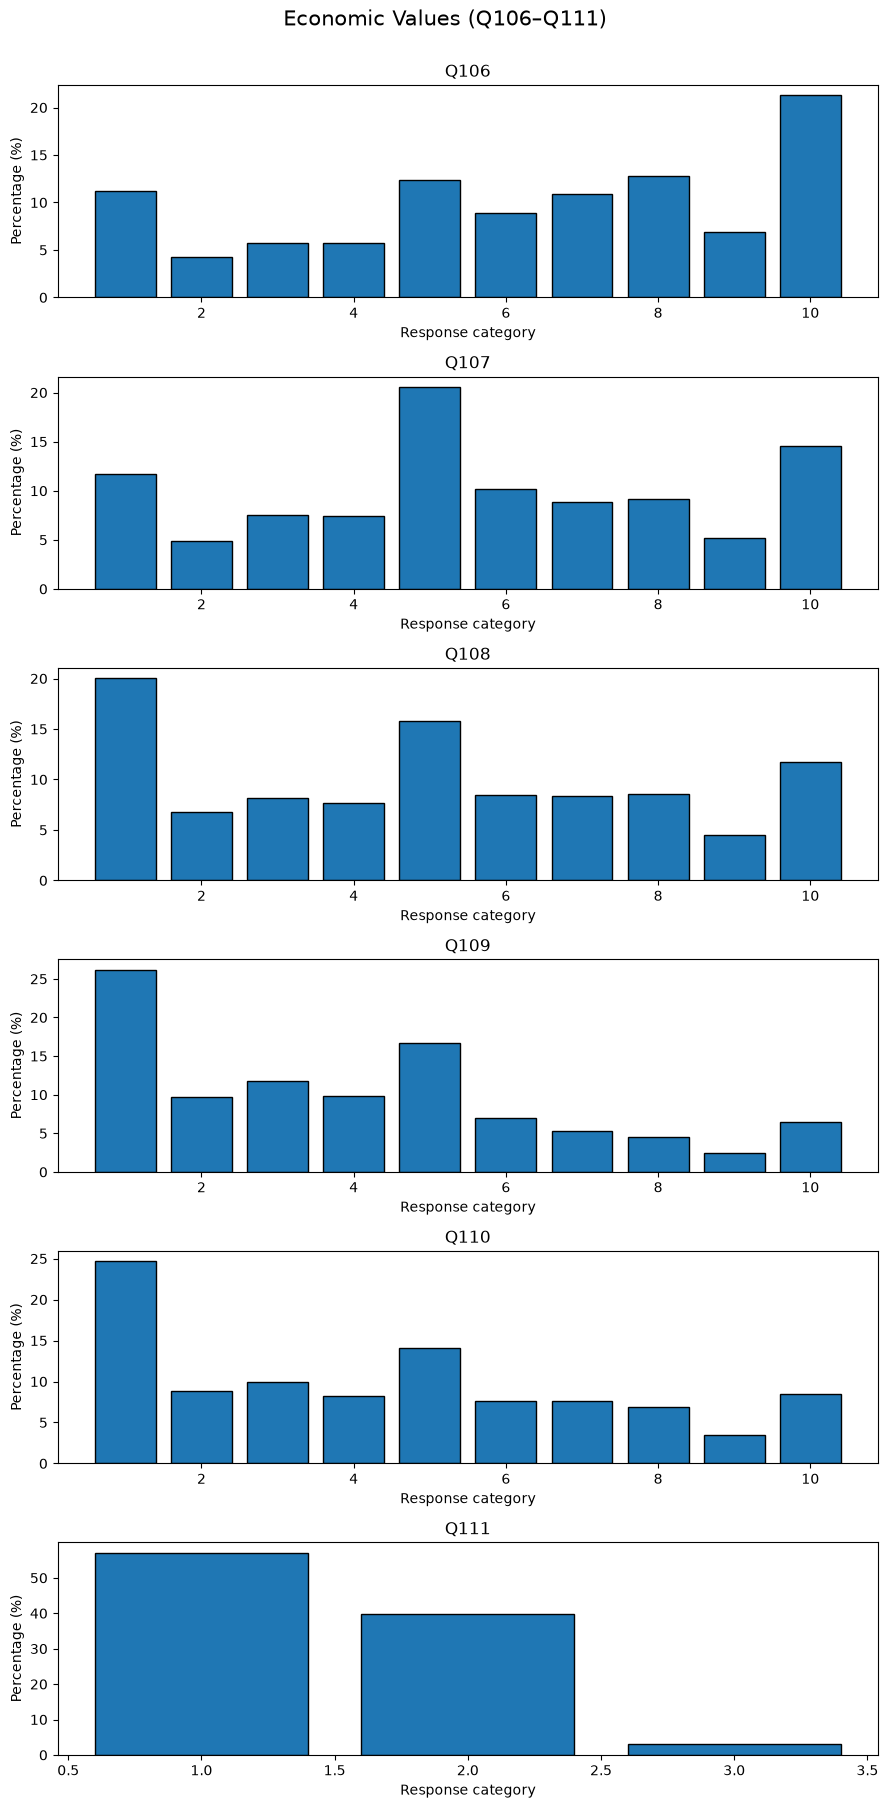

In [73]:
plot_variable_distributions(
    eda_data,
    economic_values,
    "Economic Values (Q106–Q111)"
)

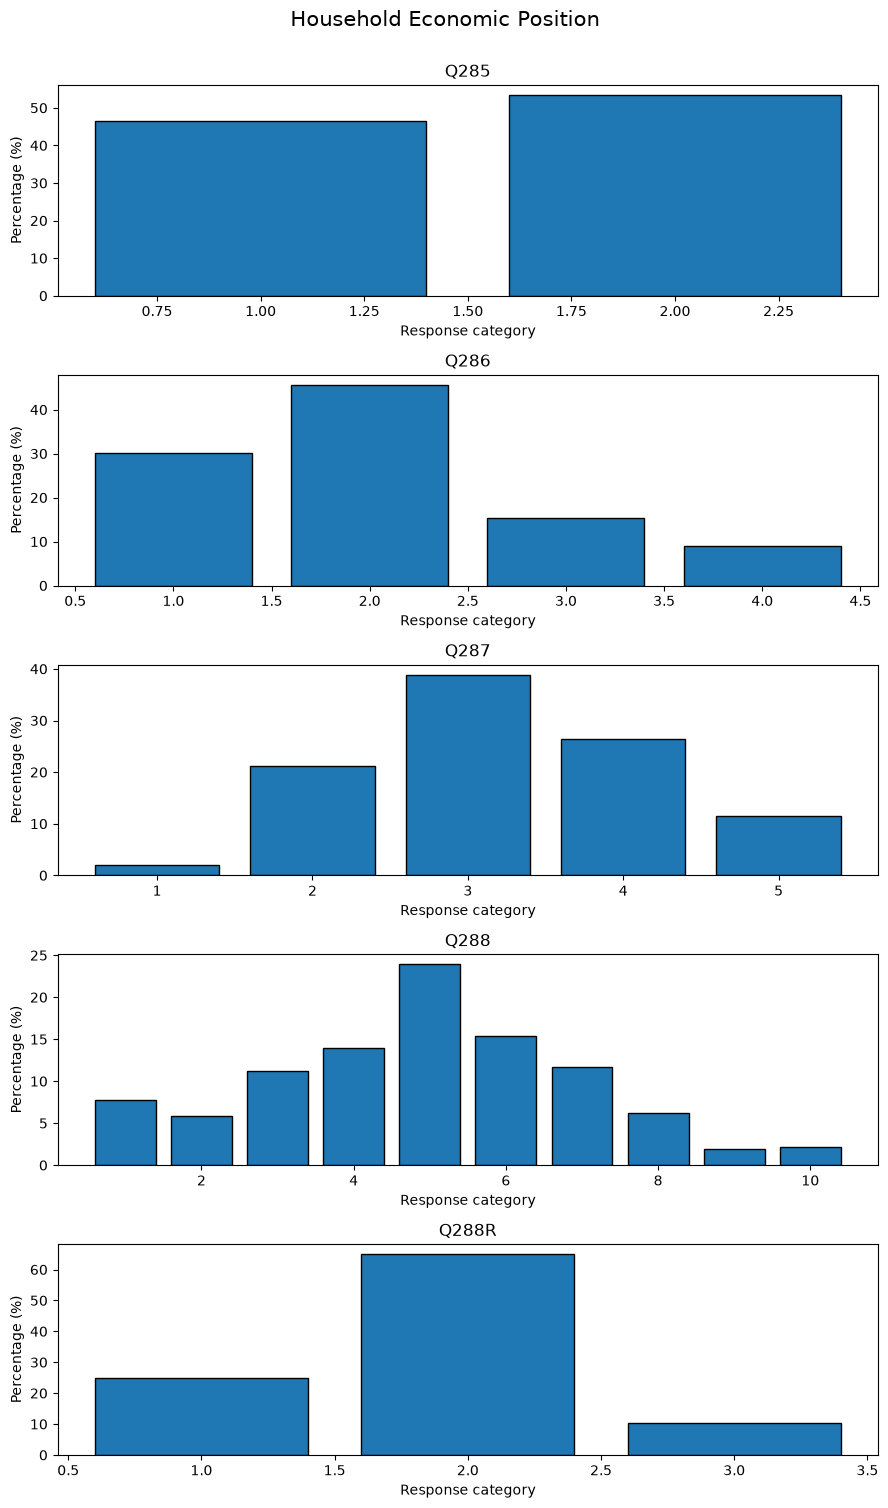

In [74]:
plot_variable_distributions(
    eda_data,
    household_economic,
    "Household Economic Position"
)

### Key Findings: Economic Variables

The univariate analysis of the 18 economic variables reveals considerable differences in response distributions.

**Economic Security (Q50–Q56)**

Q50 shows a relatively dispersed response distribution. In contrast, Q51–Q55 are more concentrated in category 4, particularly Q55, where approximately 83.6% of valid responses fall into this category. Q56 shows a different distribution, with category 1 representing approximately 55% of responses.

The direction and meaning of these response categories require confirmation from the WVS Codebook before substantive interpretation.

**Economic Values (Q106–Q111)**

Q106–Q110 show relatively dispersed responses across their 1–10 scales. Q111 is nominal and must be treated as a categorical variable rather than an ordered scale.

**Household Economic Position (Q285–Q288 and Q288R)**

The household economic variables show varying response distributions. Q288 measures relative household income position within the country, rather than absolute income. Q288R is an alternative recoded version of Q288.

Only one of these income representations should be included in a given model.

Overall, the economic variables capture several distinct dimensions of economic circumstances and attitudes. Their distributions provide a basis for further association analysis with life satisfaction.

In [75]:
master_dictionary.loc[
    master_dictionary["Variable"] == "Q56",
    "Measurement_type"
] = "Nominal"

master_dictionary.loc[
    master_dictionary["Variable"] == "Q56",
    ["Variable", "Measurement_type"]
]

,Variable,Measurement_type
54,Q56,Nominal


In [76]:
master_dictionary.to_csv(
    OUTPUT_DIR / "WVS_Master_Variable_Dictionary.csv",
    index=False
)

### Key Findings: Economic Security (Q50–Q56)

The analysis reveals different response patterns across the seven variables.

Q50, measuring satisfaction with the household's financial situation, shows a relatively dispersed distribution across the 1–10 scale.

Q51–Q55 measure the frequency of economic hardship and related insecurity during the previous 12 months. Their response categories range from "Often" (1) to "Never" (4). Responses are concentrated in category 4, indicating that most respondents reported that these difficulties had never occurred during the reference period.

Q55 shows the strongest concentration, with approximately 83.6% of valid responses in category 4.

Q56 compares respondents' current standard of living with that of their parents at a similar age. Approximately 55.0% reported being better off, 17.5% worse off and 27.5% about the same.

Q56 is treated as a nominal variable because its three response categories do not form a natural numerical order.

Overall, these variables capture different dimensions of economic circumstances, including financial satisfaction, material hardship and perceived intergenerational changes in living standards.

### Key Findings: Economic Values (Q106–Q111)

Q106–Q110 use a 1–10 scale measuring respondents' positions between two opposing economic statements. Higher scores indicate stronger agreement with the statement on the right.

The direction of each scale differs in substantive meaning:

- Q106: Greater support for larger income differences.
- Q107: Greater support for government ownership of business.
- Q108: Greater emphasis on individual responsibility.
- Q109: Greater perception that competition is harmful.
- Q110: Greater belief that success depends on luck and connections rather than hard work.

Q111 is a nominal variable measuring whether respondents prioritize environmental protection, economic growth and job creation, or another voluntarily stated position.

These variables capture different economic values and ideological orientations. Their response distributions should therefore be interpreted individually rather than combined into a single general economic score.

### Key Findings: Household Economic Position

The analysis of Q285–Q288 and Q288R reveals several dimensions of respondents' household economic position.

Q285 indicates whether the respondent is the chief wage earner in the household. Slightly more than half of valid respondents reported that they were not the chief wage earner.

Q286 measures the household's financial situation during the previous year. The most common response was "Just get by" (approximately 45.5%), followed by "Spent some savings" and other financial situations.

Q287 measures subjective social class. The most common response was "Lower middle class" (approximately 38.9%). This variable reflects perceived social position rather than an objective income measure.

Q288 measures the household's relative income position within its own country, using a scale from 1 (lowest income group) to 10 (highest income group). The most common response was category 5.

Q288R is a recoded version of Q288, grouping respondents into low, middle and high income categories. It should not be used simultaneously with Q288 in the same model.

Overall, these variables capture household financial circumstances, subjective social status and relative income position. They provide complementary information for exploring differences in life satisfaction.

## EDA Demographic & Background：Q260–Q274

In [77]:
demographic_variables = [
    f"Q{i}" for i in range(260, 275)
]

demographic_data = eda_data[demographic_variables].copy()

special_codes = [-1, -2, -3, -4, -5]

demographic_data = demographic_data.replace(
    special_codes, np.nan
)

print("Shape:", demographic_data.shape)

Shape: (97220, 15)


In [78]:
categorical_variables = [
    "Q260", "Q263", "Q264", "Q265",
    "Q269", "Q271", "Q273"
]

for variable in categorical_variables:
    print(f"\n--- {variable} ---")

    distribution = (
        demographic_data[variable]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )

    display(distribution.rename("Percentage").to_frame())


--- Q260 ---


,Percentage
Q260,
1.0,47.36
2.0,52.64



--- Q263 ---


,Percentage
Q263,
1.0,94.15
2.0,5.85



--- Q264 ---


,Percentage
Q264,
1.0,90.31
2.0,9.69


... (4 outputs left out)


--- Q271 ---


,Percentage
Q271,
1.0,70.66
2.0,24.01
3.0,4.71
4.0,0.62



--- Q273 ---


,Percentage
Q273,
1.0,55.70
2.0,7.90
3.0,4.45
4.0,2.17
5.0,5.72
6.0,24.06


In [79]:
numeric_variables = [
    "Q261", "Q262", "Q270", "Q274"
]

display(
    demographic_data[numeric_variables]
    .describe()
    .round(2)
)

,Q261,Q262,Q270,Q274
count,95636.00,96709.00,96235.00,92364.00
mean,1975.64,43.18,4.02,1.77
std,16.67,16.58,2.57,1.72
min,1916.00,16.00,1.00,0.00
25%,1963.00,29.00,2.00,0.00
50%,1978.00,41.00,4.00,2.00
75%,1990.00,55.00,5.00,3.00
max,2007.00,103.00,63.00,24.00


In [80]:
numeric_variables = ["Q261", "Q262", "Q270", "Q274"]

for variable in numeric_variables:
    print(f"\n--- {variable} ---")

    print("Largest values:")
    display(
        demographic_data[variable]
        .value_counts()
        .sort_index()
        .tail(10)
    )

    print("95th percentile:",
          demographic_data[variable].quantile(0.95))

    print("99th percentile:",
          demographic_data[variable].quantile(0.99))


--- Q261 ---
Largest values:


Q261
1998.0    1959
1999.0    1887
2000.0    1636
2001.0     899
2002.0     583
2003.0     297
2004.0      87
2005.0      30
2006.0     166
2007.0     155
Name: count, dtype: int64

95th percentile: 1999.0
99th percentile: 2002.0

--- Q262 ---
Largest values:


Q262
91.0     34
92.0     15
93.0     11
94.0     10
95.0      5
96.0      2
98.0      1
99.0     11
100.0     1
103.0     1
Name: count, dtype: int64

95th percentile: 72.0
99th percentile: 82.0

--- Q270 ---
Largest values:


Q270
25.0    8
26.0    3
27.0    1
29.0    2
30.0    6
32.0    1
35.0    1
40.0    2
41.0    1
63.0    1
Name: count, dtype: int64

95th percentile: 8.0
99th percentile: 13.0

--- Q274 ---
Largest values:


Q274
13.0    11
14.0    11
15.0     8
16.0     2
17.0     2
18.0     4
21.0     3
22.0     6
23.0     1
24.0     1
Name: count, dtype: int64

95th percentile: 5.0
99th percentile: 7.0


In [81]:
q270_extreme = eda_data.loc[
    eda_data["Q270"] >= 25,
    [
        "B_COUNTRY_ALPHA",
        "Q260",
        "Q262",
        "Q270",
        "Q273",
        "Q274"
    ]
].sort_values("Q270", ascending=False)

display(q270_extreme)

,B_COUNTRY_ALPHA,Q260,Q262,Q270,Q273,Q274
61045,NGA,1,20,63,6,0
50482,LBY,2,71,41,1,3
60623,MYS,2,37,40,3,0
61360,NGA,1,28,40,1,3
62036,NGA,1,20,35,6,0
51611,LBY,2,38,32,6,-1
46161,KEN,1,21,30,6,0
7137,BOL,1,67,30,1,7
62013,NGA,1,24,30,6,0
60868,NGA,1,60,30,1,4


In [82]:
print("A_YEAR exists:", "A_YEAR" in eda_data.columns)

if "A_YEAR" in eda_data.columns:
    display(eda_data["A_YEAR"].describe())

A_YEAR exists: False


In [83]:
import pandas as pd

year_data = pd.read_csv(
    DATA_FILE,
    usecols=["A_YEAR", "Q261", "Q262"],
)

print("Shape:", year_data.shape)

display(year_data.head())
display(year_data["A_YEAR"].value_counts().sort_index())

Shape: (97220, 3)


,A_YEAR,Q261,Q262
0,2018,1958,60
1,2018,1971,47
2,2018,1969,48
3,2018,1956,62
4,2018,1969,49


A_YEAR
2017     9722
2018    40647
2019     7007
2020    21187
2021     5918
2022    11047
2023     1692
Name: count, dtype: int64

In [84]:
# Create a temporary copy
age_check = year_data.copy()

# Remove special codes
age_check = age_check.replace(
    special_codes, np.nan
).dropna()

# Calculate estimated age
age_check["Estimated_Age"] = (
    age_check["A_YEAR"] - age_check["Q261"]
)

# Compare reported and estimated age
age_check["Age_Difference"] = (
    age_check["Q262"] - age_check["Estimated_Age"]
)

display(age_check.head(10))

,A_YEAR,Q261,Q262,Estimated_Age,Age_Difference
0,2018,1958.0,60.0,60.0,0.0
1,2018,1971.0,47.0,47.0,0.0
2,2018,1969.0,48.0,49.0,-1.0
3,2018,1956.0,62.0,62.0,0.0
4,2018,1969.0,49.0,49.0,0.0
5,2018,1967.0,51.0,51.0,0.0
6,2018,1985.0,33.0,33.0,0.0
7,2018,1963.0,55.0,55.0,0.0
8,2018,1978.0,40.0,40.0,0.0
9,2018,1979.0,38.0,39.0,-1.0


In [85]:
print("Age difference distribution:")

display(
    age_check["Age_Difference"]
    .value_counts()
    .sort_index()
)

print("\nAge difference statistics:")

display(
    age_check["Age_Difference"]
    .describe()
)

Age difference distribution:


Age_Difference
-50.0        1
-33.0        1
-30.0        3
-20.0        2
-18.0        1
-13.0        1
-11.0        1
-10.0        4
-9.0         1
-8.0         2
-7.0         4
-6.0         4
-5.0         5
-4.0         4
-3.0         9
-2.0       168
-1.0     30801
 0.0     64096
 1.0       471
 2.0        24
 3.0         6
 4.0         2
 5.0         4
 6.0         2
 8.0         1
 9.0         2
 14.0        1
 19.0        2
 20.0        2
 26.0        1
 30.0        1
 49.0        1
Name: count, dtype: int64


Age difference statistics:


count    95628.000000
mean        -0.321841
std          0.624007
min        -50.000000
25%         -1.000000
50%          0.000000
75%          0.000000
max         49.000000
Name: Age_Difference, dtype: float64

In [86]:
age_check["Age_consistency"] = np.select(
    [
        age_check["Age_Difference"] == 0,
        age_check["Age_Difference"].abs() == 1
    ],
    [
        "Exact match",
        "Difference of 1 year"
    ],
    default="Difference greater than 1 year"
)

display(
    age_check["Age_consistency"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Percentage")
    .to_frame()
)

,Percentage
Age_consistency,
Exact match,67.03
Difference of 1 year,32.70
Difference greater than 1 year,0.27


In [87]:
age_check = pd.read_csv(
    DATA_FILE,
    usecols=[
        "B_COUNTRY_ALPHA",
        "A_YEAR",
        "Q261",
        "Q262"
    ]
)

age_check = age_check.replace(
    special_codes, np.nan
).dropna()

age_check["Estimated_Age"] = (
    age_check["A_YEAR"] - age_check["Q261"]
)

age_check["Age_Difference"] = (
    age_check["Q262"] - age_check["Estimated_Age"]
)

In [88]:
age_outliers = age_check.loc[
    age_check["Age_Difference"].abs() > 1
].copy()

print("Number of records:", len(age_outliers))

display(
    age_outliers.sort_values(
        "Age_Difference"
    )
)

Number of records: 260


,A_YEAR,B_COUNTRY_ALPHA,Q261,Q262,Estimated_Age,Age_Difference
29374,2022,GBR,1936.0,36.0,86.0,-50.0
89604,2022,URY,1946.0,43.0,76.0,-33.0
13428,2020,CAN,1949.0,41.0,71.0,-30.0
93091,2022,UZB,1950.0,42.0,72.0,-30.0
93099,2022,UZB,1966.0,26.0,56.0,-30.0
...,...,...,...,...,...,...
29219,2022,GBR,1989.0,53.0,33.0,20.0
29206,2022,GBR,1990.0,52.0,32.0,20.0
11636,2020,CAN,1958.0,88.0,62.0,26.0
29513,2022,GBR,1996.0,56.0,26.0,30.0


In [89]:
display(
    age_outliers.groupby("B_COUNTRY_ALPHA")
    .agg(
        Outlier_count=("Age_Difference", "count"),
        Mean_difference=("Age_Difference", "mean"),
        Max_difference=("Age_Difference", "max"),
        Min_difference=("Age_Difference", "min")
    )
    .sort_values("Outlier_count", ascending=False)
)

,Outlier_count,Mean_difference,Max_difference,Min_difference
B_COUNTRY_ALPHA,,,,
NIC,91,-2.000000,-2.0,-2.0
URY,37,-1.270270,49.0,-33.0
UZB,31,-3.258065,6.0,-30.0
CAN,23,-4.130435,26.0,-30.0
CHL,17,-2.000000,-2.0,-2.0
GBR,16,2.125000,30.0,-50.0
MAR,15,-0.466667,2.0,-3.0
MEX,10,-0.400000,2.0,-2.0
PER,4,-1.000000,2.0,-2.0


In [90]:
# Count age differences by country
country_age_difference = pd.crosstab(
    age_outliers["B_COUNTRY_ALPHA"],
    age_outliers["Age_Difference"]
)

display(country_age_difference)

Age_Difference,-50.0,-33.0,-30.0,-20.0,-18.0,-13.0,-11.0,-10.0,-9.0,-8.0,...,5.0,6.0,8.0,9.0,14.0,19.0,20.0,26.0,30.0,49.0
B_COUNTRY_ALPHA,,,,,,,,,,,,,,,,,,,,,
CAN,0,0,1,0,1,1,0,2,0,1,...,0,0,0,0,0,0,0,1,0,0
CHL,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CHN,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GBR,1,0,0,1,0,0,0,1,0,0,...,1,0,0,0,1,2,2,0,1,0
KEN,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
MAR,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
MDV,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
MEX,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
NIC,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [91]:
countries_to_check = [
    "NIC", "CHL", "URY", "UZB", "CAN", "GBR"
]

display(
    age_check[
        age_check["B_COUNTRY_ALPHA"].isin(countries_to_check)
    ]
    .groupby("B_COUNTRY_ALPHA")
    .agg(
        Respondents=("Age_Difference", "count"),
        Mean_difference=("Age_Difference", "mean"),
        Min_difference=("Age_Difference", "min"),
        Max_difference=("Age_Difference", "max"),
        Exact_match_percentage=(
            "Age_Difference",
            lambda x: (x == 0).mean() * 100
        )
    )
    .round(2)
)

,Respondents,Mean_difference,Min_difference,Max_difference,Exact_match_percentage
B_COUNTRY_ALPHA,,,,,
CAN,4018,-0.23,-30.0,26.0,78.10
CHL,1000,-0.85,-2.0,0.0,17.10
GBR,2445,-0.47,-50.0,30.0,51.21
NIC,1200,-1.08,-2.0,-1.0,0.00
URY,999,-0.84,-33.0,49.0,15.42
UZB,1249,-0.20,-30.0,6.0,81.27


In [92]:
age_check["Difference_group"] = "Greater than 1 year"

age_check.loc[
    age_check["Age_Difference"].abs() <= 1,
    "Difference_group"
] = "Within 1 year"

In [93]:
year_consistency = pd.crosstab(
    age_check["A_YEAR"],
    age_check["Difference_group"],
    normalize="index"
) * 100

display(year_consistency.round(2))

Difference_group,Greater than 1 year,Within 1 year
A_YEAR,,
2017,0.00,100.00
2018,0.08,99.92
2019,0.00,100.00
2020,0.56,99.44
2021,0.36,99.64
2022,0.81,99.19
2023,0.00,100.00


In [94]:
display(
    age_check.groupby("A_YEAR")
    .agg(
        Respondents=("Age_Difference", "count"),
        Mean_difference=("Age_Difference", "mean"),
        Exact_match_percentage=(
            "Age_Difference",
            lambda x: (x == 0).mean() * 100
        )
    )
    .round(2)
)

,Respondents,Mean_difference,Exact_match_percentage
A_YEAR,,,
2017,9719,-0.18,81.91
2018,39534,-0.34,65.30
2019,6793,-0.24,75.98
2020,21145,-0.39,61.97
2021,5908,-0.15,73.53
2022,10837,-0.44,55.57
2023,1692,-0.00,99.94


### Age Consistency and Data Quality

The consistency between year of birth (Q261) and reported age (Q262) was assessed using the survey year (A_YEAR).

Among respondents with valid information for all three variables:

- 67.03% had an exact match between reported and estimated age.
- 32.70% differed by one year.
- 0.27% (260 records) differed by more than one year.

Differences of one year may reflect whether respondents had already celebrated their birthday at the time of the interview.

Larger discrepancies were concentrated in a limited number of countries. Nicaragua and Chile showed systematic differences of one to two years, while some records in Canada, Great Britain, Uruguay and Uzbekistan showed larger discrepancies.

The proportion of discrepancies greater than one year varied across survey years, reaching 0.81% in 2022. However, survey year and country composition are related, so these differences should not be interpreted as evidence of changes in data quality over time.

For subsequent modeling, Q262 (reported age) will be preferred over Q261 (year of birth) to avoid redundant predictors. No records were removed or modified during this exploratory quality assessment.

### EDA Educational Background

In [95]:
education_dictionary = master_dictionary.loc[
    master_dictionary["Feature_group"] == "Educational Background"
].copy()

education_variables = education_dictionary["Variable"].tolist()

print("Number of education variables:", len(education_variables))

display(
    missing_summary.loc[
        education_variables,
        [
            "Missing_percentage",
            "Valid_response_count",
            "Countries_with_valid_responses",
            "Country_coverage_percentage"
        ]
    ].sort_values("Missing_percentage", ascending=False)
)

Number of education variables: 12


,Missing_percentage,Valid_response_count,Countries_with_valid_responses,Country_coverage_percentage
Q276A,64.809710,34212,37,56.060606
Q278A,51.734211,46924,37,56.060606
Q277A,51.047110,47592,37,56.060606
Q275A,44.253240,54197,39,59.090909
Q276R,36.534664,61701,63,95.454545
Q276,36.502777,61732,63,95.454545
Q278R,14.087636,83524,63,95.454545
Q278,14.035178,83575,63,95.454545
Q277R,12.775149,84800,63,95.454545
Q277,12.732977,84841,63,95.454545


In [96]:
standard_education_variables = [
    "Q275", "Q276", "Q277", "Q278"
]

education_data = eda_data[
    standard_education_variables
].copy()

education_data = education_data.replace(
    special_codes, np.nan
)

print("Education data shape:", education_data.shape)

Education data shape: (97220, 4)


In [97]:
for variable in standard_education_variables:

    print(f"\n--- {variable} ---")

    display(
        education_data[variable]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
        .rename("Percentage")
        .to_frame()
    )


--- Q275 ---


,Percentage
Q275,
0.0,5.09
1.0,11.72
2.0,14.90
3.0,25.70
4.0,9.20
5.0,8.13
6.0,17.60
7.0,6.48
8.0,1.18



--- Q276 ---


,Percentage
Q276,
0.0,6.98
1.0,14.32
2.0,15.98
3.0,25.64
4.0,9.30
5.0,7.22
6.0,13.68
7.0,5.67
8.0,1.16



--- Q277 ---


,Percentage
Q277,
0.0,22.77
1.0,25.09
2.0,15.88
3.0,18.49
4.0,5.49
5.0,3.87
6.0,5.29
7.0,2.54
8.0,0.54



--- Q278 ---


,Percentage
Q278,
0.0,20.18
1.0,24.68
2.0,15.55
3.0,18.65
4.0,6.29
5.0,4.15
6.0,6.23
7.0,3.28
8.0,0.93


In [98]:
alternative_education_variables = [
    "Q275R", "Q276R", "Q277R", "Q278R"
]

for variable in alternative_education_variables:

    print(f"\n--- {variable} ---")

    display(
        eda_data[variable]
        .replace(special_codes, np.nan)
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
        .rename("Percentage")
        .to_frame()
    )


--- Q275R ---


,Percentage
Q275R,
1.0,31.71
2.0,34.90
3.0,33.39



--- Q276R ---


,Percentage
Q276R,
1.0,37.30
2.0,34.96
3.0,27.74



--- Q277R ---


,Percentage
Q277R,
1.0,63.77
2.0,23.99
3.0,12.24



--- Q278R ---


,Percentage
Q278R,
1.0,60.45
2.0,24.95
3.0,14.60


## 4.X Education and Life Satisfaction

Explore the relationship between respondents' educational attainment (Q275)
and life satisfaction (Q49).

The analysis compares mean life satisfaction across ISCED 2011 education levels.

In [99]:
# Select the two variables
education_satisfaction = eda_data[["Q275", "Q49"]].copy()

# Replace special codes with NaN
education_satisfaction = education_satisfaction.replace(
    special_codes, np.nan
)

# Keep valid education levels and life satisfaction scores
education_satisfaction = education_satisfaction.dropna()

education_satisfaction = education_satisfaction[
    education_satisfaction["Q275"].between(0, 8)
    & education_satisfaction["Q49"].between(1, 10)
]

# Calculate statistics by education level
education_satisfaction_summary = (
    education_satisfaction
    .groupby("Q275")["Q49"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(education_satisfaction_summary)

,count,mean,median,std
Q275,,,,
0.0,4863,6.69,7.0,2.61
1.0,11240,6.92,7.0,2.55
2.0,14274,6.99,7.0,2.34
3.0,24616,7.10,7.0,2.24
4.0,8776,6.97,7.0,2.19
5.0,7780,7.05,7.0,2.17
6.0,16839,7.23,7.0,1.93
7.0,6203,7.30,8.0,1.96
8.0,1126,7.27,8.0,1.97


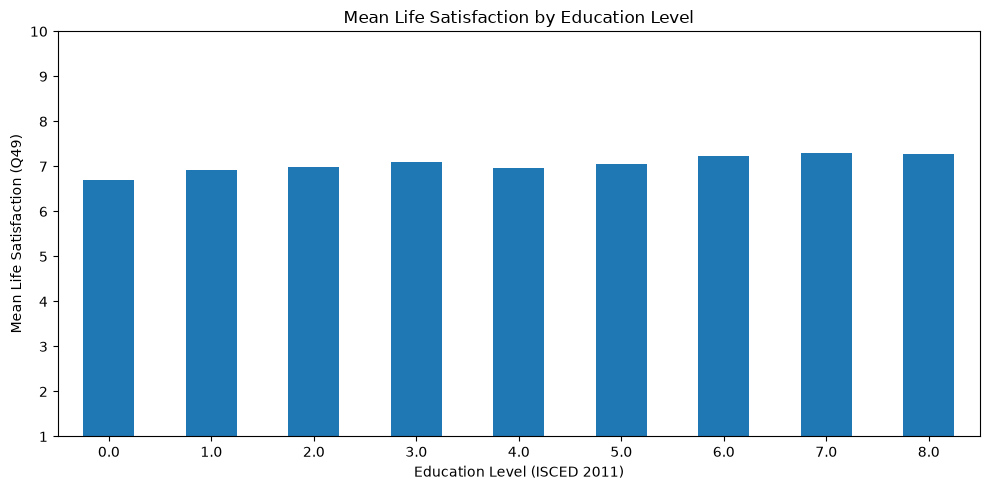

In [100]:
import matplotlib.pyplot as plt

education_satisfaction_summary["mean"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Mean Life Satisfaction by Education Level")
plt.xlabel("Education Level (ISCED 2011)")
plt.ylabel("Mean Life Satisfaction (Q49)")
plt.xticks(rotation=0)
plt.ylim(1, 10)
plt.tight_layout()
plt.show()

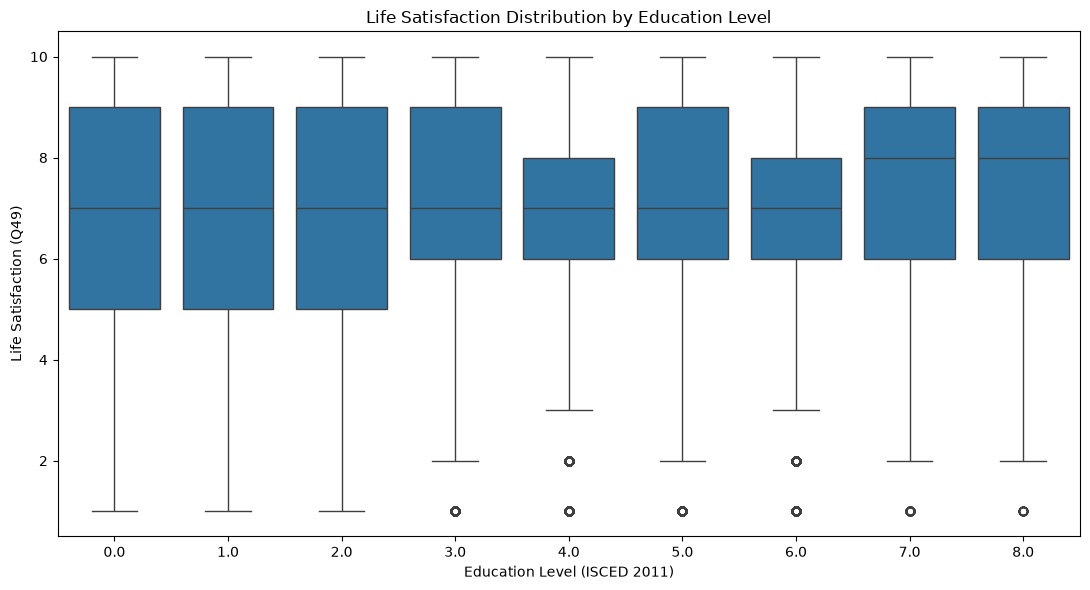

In [101]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=education_satisfaction,
    x="Q275",
    y="Q49"
)

plt.title("Life Satisfaction Distribution by Education Level")
plt.xlabel("Education Level (ISCED 2011)")
plt.ylabel("Life Satisfaction (Q49)")
plt.ylim(0.5, 10.5)
plt.tight_layout()
plt.show()

In [102]:
education_satisfaction_summary = (
    education_satisfaction
    .groupby("Q275")["Q49"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
    .round(2)
)

display(education_satisfaction_summary)

,count,mean,median,std,q1,q3
Q275,,,,,,
0.0,4863,6.69,7.0,2.61,5.0,9.0
1.0,11240,6.92,7.0,2.55,5.0,9.0
2.0,14274,6.99,7.0,2.34,5.0,9.0
3.0,24616,7.10,7.0,2.24,6.0,9.0
4.0,8776,6.97,7.0,2.19,6.0,8.0
5.0,7780,7.05,7.0,2.17,6.0,9.0
6.0,16839,7.23,7.0,1.93,6.0,8.0
7.0,6203,7.30,8.0,1.96,6.0,9.0
8.0,1126,7.27,8.0,1.97,6.0,9.0


In [103]:
education_satisfaction_summary["sample_percentage"] = (
    education_satisfaction_summary["count"]
    / education_satisfaction_summary["count"].sum()
    * 100
).round(2)

display(education_satisfaction_summary)

,count,mean,median,std,q1,q3,sample_percentage
Q275,,,,,,,
0.0,4863,6.69,7.0,2.61,5.0,9.0,5.08
1.0,11240,6.92,7.0,2.55,5.0,9.0,11.74
2.0,14274,6.99,7.0,2.34,5.0,9.0,14.91
3.0,24616,7.10,7.0,2.24,6.0,9.0,25.72
4.0,8776,6.97,7.0,2.19,6.0,8.0,9.17
5.0,7780,7.05,7.0,2.17,6.0,9.0,8.13
6.0,16839,7.23,7.0,1.93,6.0,8.0,17.59
7.0,6203,7.30,8.0,1.96,6.0,9.0,6.48
8.0,1126,7.27,8.0,1.97,6.0,9.0,1.18


### Education and Life Satisfaction – Preliminary Findings

The analysis of 95,717 respondents shows a modest positive association between educational attainment and life satisfaction.

Mean life satisfaction generally increases from 6.69 among respondents with no formal education or early childhood education to 7.30 among those with a master's degree. However, the relationship is not strictly linear, as respondents with doctoral degrees report a slightly lower mean score (7.27).

The median life satisfaction score is 7 for education levels ISCED 0–6 and 8 for ISCED 7–8. The distributions overlap considerably, suggesting that educational differences in life satisfaction are relatively modest.

Standard deviations are also higher among respondents with lower educational attainment, indicating greater variation in reported life satisfaction within these groups.

These findings are descriptive and do not establish a causal relationship. Country differences, household income, age, and other social factors may help explain the observed patterns.

## Economic Position and Life Satisfaction

Explore the relationship between respondents' relative
household income position (Q288) and life satisfaction (Q49).

Q288 measures household income position relative to others
within the respondent's country, using a scale from 1 to 10.

In [104]:
income_satisfaction = eda_data[["Q288", "Q49"]].copy()

income_satisfaction = income_satisfaction.replace(
    special_codes, np.nan
)

income_satisfaction = income_satisfaction.dropna()

income_satisfaction = income_satisfaction[
    income_satisfaction["Q288"].between(1, 10)
    & income_satisfaction["Q49"].between(1, 10)
]

income_satisfaction_summary = (
    income_satisfaction
    .groupby("Q288")["Q49"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(income_satisfaction_summary)

,count,mean,median,std
Q288,,,,
1.0,7238,6.44,7.0,3.14
2.0,5469,6.39,7.0,2.57
3.0,10548,6.52,7.0,2.34
4.0,13097,6.73,7.0,2.13
5.0,22462,7.13,7.0,2.14
6.0,14478,7.26,7.0,1.90
7.0,10982,7.52,8.0,1.83
8.0,5783,7.79,8.0,1.85
9.0,1819,7.93,8.0,1.86


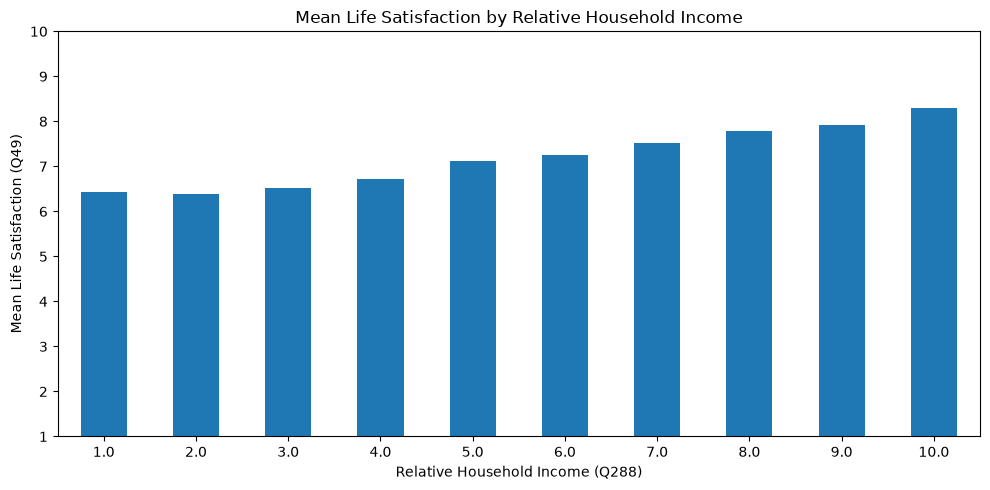

In [105]:
income_satisfaction_summary["mean"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Mean Life Satisfaction by Relative Household Income")
plt.xlabel("Relative Household Income (Q288)")
plt.ylabel("Mean Life Satisfaction (Q49)")
plt.xticks(rotation=0)
plt.ylim(1, 10)
plt.tight_layout()
plt.show()

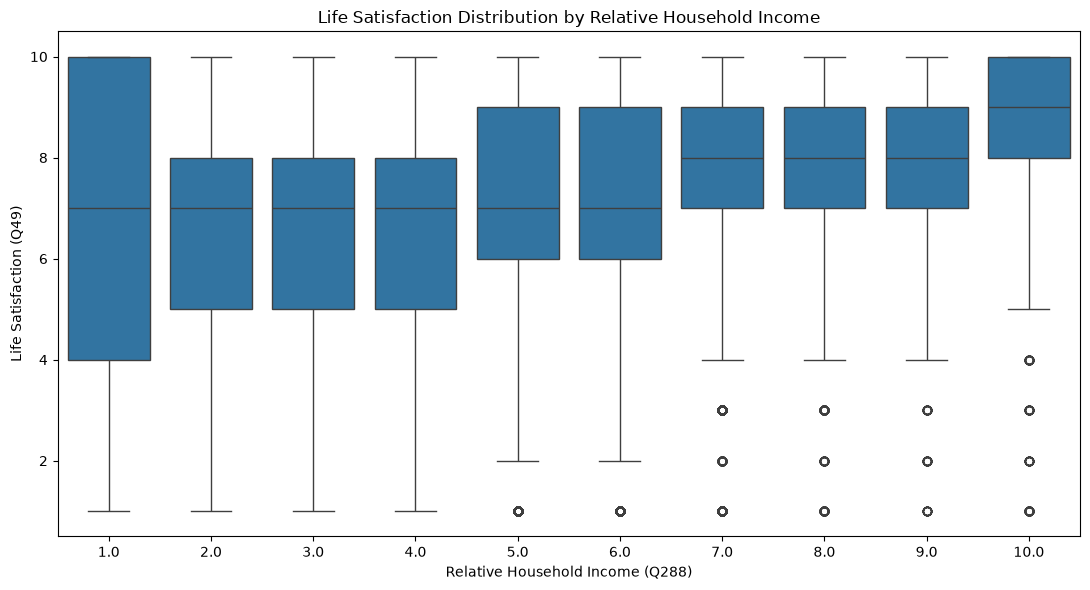

In [106]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=income_satisfaction,
    x="Q288",
    y="Q49"
)

plt.title("Life Satisfaction Distribution by Relative Household Income")
plt.xlabel("Relative Household Income (Q288)")
plt.ylabel("Life Satisfaction (Q49)")
plt.ylim(0.5, 10.5)
plt.tight_layout()
plt.show()

### Relative Household Income and Life Satisfaction – Preliminary Findings

The analysis shows a clear positive association between relative household income position and life satisfaction.

Mean life satisfaction increases from 6.44 among respondents in the lowest relative income group (Q288 = 1) to 8.30 among those in the highest group (Q288 = 10), representing a difference of 1.86 points on the 10-point life satisfaction scale.

The relationship is generally increasing, although it is not strictly monotonic, as the mean score for income group 2 is slightly lower than that for group 1.

The standard deviation is highest in the lowest income group (3.14) and generally lower among higher-income groups. This suggests greater variation in life satisfaction among respondents in lower relative income positions.

These results indicate a stronger descriptive association between relative household income and life satisfaction than was observed for educational attainment. However, the pooled results do not establish causality and may partly reflect differences between countries and other respondent characteristics.

## Country-Level Relationship Between Income and Life Satisfaction

Examine whether the association between relative household
income position (Q288) and life satisfaction (Q49) is
consistent across countries.

Spearman correlation is calculated separately for each
country to explore within-country relationships.

In [107]:
from scipy.stats import spearmanr

country_income_data = eda_data[
    ["B_COUNTRY_ALPHA", "Q288", "Q49"]
].copy()

country_income_data = country_income_data.replace(
    special_codes, np.nan
)

country_income_data = country_income_data.dropna()

country_income_data = country_income_data[
    country_income_data["Q288"].between(1, 10)
    & country_income_data["Q49"].between(1, 10)
]

country_income_results = []

for country, group in country_income_data.groupby("B_COUNTRY_ALPHA"):

    if len(group) >= 30 and group["Q288"].nunique() > 1:

        rho, p_value = spearmanr(
            group["Q288"],
            group["Q49"]
        )

        country_income_results.append({
            "Country": country,
            "Sample_size": len(group),
            "Spearman_rho": rho,
            "p_value": p_value
        })

country_income_corr = pd.DataFrame(country_income_results)

country_income_corr = country_income_corr.sort_values(
    "Spearman_rho",
    ascending=False
)

display(country_income_corr)

,Country,Sample_size,Spearman_rho,p_value
24,IRQ,1200,0.982909,0.000000e+00
18,GRC,1151,0.415490,2.945852e-49
7,CAN,4018,0.373448,3.500831e-133
12,CZE,1186,0.347374,5.753804e-35
52,SRB,977,0.312244,1.549649e-23
...,...,...,...,...
63,VEN,1190,0.032815,2.580057e-01
8,CHL,965,0.009238,7.744067e-01
6,BRA,1638,-0.002403,9.225836e-01
36,MEX,1719,-0.005202,8.293680e-01


In [108]:
irq_data = country_income_data[
    country_income_data["B_COUNTRY_ALPHA"] == "IRQ"
].copy()

print("Sample size:", len(irq_data))

print("\nQ288 distribution:")
display(irq_data["Q288"].value_counts().sort_index())

print("\nQ49 distribution:")
display(irq_data["Q49"].value_counts().sort_index())

print("\nCross-tabulation: Q288 vs Q49")

display(
    pd.crosstab(
        irq_data["Q288"],
        irq_data["Q49"]
    )
)

Sample size: 1200

Q288 distribution:


Q288
1.0      48
2.0      63
3.0     247
4.0     299
5.0     355
6.0      28
7.0      65
8.0      46
9.0      22
10.0     27
Name: count, dtype: int64


Q49 distribution:


Q49
1.0      51
2.0      64
3.0     251
4.0     296
5.0     357
6.0      24
7.0      45
8.0      47
9.0      28
10.0     37
Name: count, dtype: int64


Cross-tabulation: Q288 vs Q49


Q49,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0
Q288,,,,,,,,,,
1.0,48,0,0,0,0,0,0,0,0,0
2.0,2,61,0,0,0,0,0,0,0,0
3.0,1,1,245,0,0,0,0,0,0,0
4.0,0,2,3,290,3,1,0,0,0,0
5.0,0,0,3,5,336,4,7,0,0,0
6.0,0,0,0,1,9,10,6,2,0,0
7.0,0,0,0,0,9,9,20,19,6,2
8.0,0,0,0,0,0,0,12,19,10,5
9.0,0,0,0,0,0,0,0,7,7,8


In [109]:
print("Number of countries:", len(country_income_corr))

print(
    "Positive correlations:",
    (country_income_corr["Spearman_rho"] > 0).sum()
)

print(
    "Negative correlations:",
    (country_income_corr["Spearman_rho"] < 0).sum()
)

print(
    "Strong positive correlations (rho >= 0.30):",
    (country_income_corr["Spearman_rho"] >= 0.30).sum()
)

print(
    "Weak correlations (-0.10 to 0.10):",
    country_income_corr["Spearman_rho"].between(-0.10, 0.10).sum()
)

print("\nDescriptive statistics:")

display(
    country_income_corr["Spearman_rho"].describe().round(3)
)

Number of countries: 66
Positive correlations: 63
Negative correlations: 3
Strong positive correlations (rho >= 0.30): 9
Weak correlations (-0.10 to 0.10): 13

Descriptive statistics:


count    66.000
mean      0.192
std       0.136
min      -0.010
25%       0.115
50%       0.187
75%       0.241
max       0.983
Name: Spearman_rho, dtype: float64

In [110]:
# Overall country-level correlation statistics
all_country_stats = country_income_corr["Spearman_rho"].describe()

# Sensitivity analysis: exclude IRQ
without_irq = country_income_corr[
    country_income_corr["Country"] != "IRQ"
]

without_irq_stats = without_irq["Spearman_rho"].describe()

print("All countries:")
display(all_country_stats.round(3))

print("\nExcluding IRQ:")
display(without_irq_stats.round(3))

print(
    "\nPositive correlations excluding IRQ:",
    (without_irq["Spearman_rho"] > 0).sum()
)

print(
    "Negative correlations excluding IRQ:",
    (without_irq["Spearman_rho"] < 0).sum()
)

All countries:


count    66.000
mean      0.192
std       0.136
min      -0.010
25%       0.115
50%       0.187
75%       0.241
max       0.983
Name: Spearman_rho, dtype: float64


Excluding IRQ:


count    65.000
mean      0.180
std       0.094
min      -0.010
25%       0.113
50%       0.187
75%       0.237
max       0.415
Name: Spearman_rho, dtype: float64


Positive correlations excluding IRQ: 62
Negative correlations excluding IRQ: 3


### Sensitivity Analysis: Excluding Iraq (IRQ)

A sensitivity analysis was conducted to examine whether the country-level relationship between relative household income and life satisfaction was disproportionately influenced by Iraq (IRQ), which showed an unusually high Spearman correlation coefficient of 0.983.

After excluding Iraq, the mean country-level Spearman correlation decreased slightly from 0.192 to 0.180, while the median remained unchanged at 0.187.

The standard deviation decreased from 0.136 to 0.094, and the maximum correlation decreased from 0.983 to 0.415.

Furthermore, 62 out of 65 countries (95.4%) continued to show positive correlations.

These results suggest that the generally positive association between relative household income and life satisfaction is not driven solely by the unusually strong result observed in Iraq. However, the substantial variation across countries indicates that the strength of this relationship differs between national contexts.

Iraq is retained in the overall dataset but treated as a special case in sensitivity analysis.

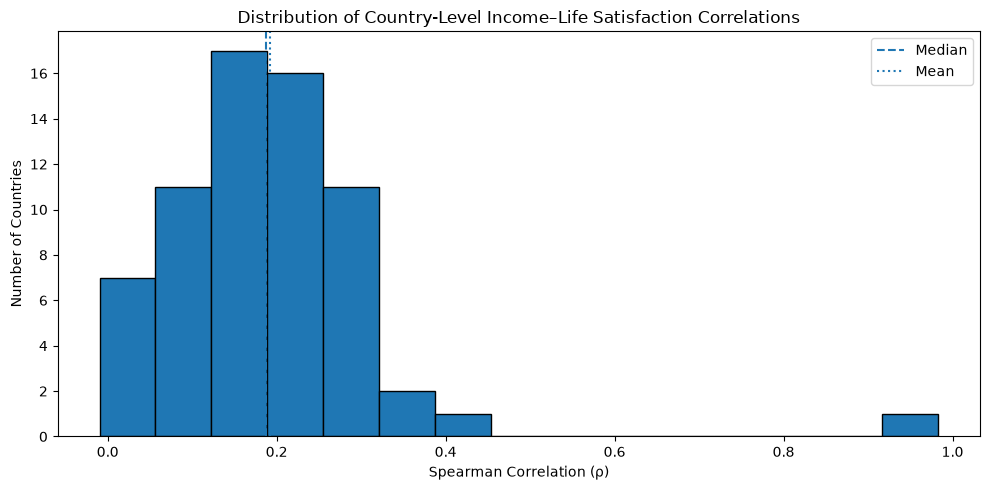

In [111]:
plt.figure(figsize=(10, 5))

plt.hist(
    country_income_corr["Spearman_rho"],
    bins=15,
    edgecolor="black"
)

plt.axvline(
    country_income_corr["Spearman_rho"].median(),
    linestyle="--",
    label="Median"
)

plt.axvline(
    country_income_corr["Spearman_rho"].mean(),
    linestyle=":",
    label="Mean"
)

plt.title("Distribution of Country-Level Income–Life Satisfaction Correlations")
plt.xlabel("Spearman Correlation (ρ)")
plt.ylabel("Number of Countries")
plt.legend()
plt.tight_layout()
plt.show()

### Distribution of Country-Level Correlations

The distribution of country-level Spearman correlations shows that the relationship between relative household income and life satisfaction is generally positive but varies considerably across countries.

Most countries have correlation coefficients between approximately 0.10 and 0.30, with a median of 0.187.

The distribution is right-skewed, partly due to an unusually high correlation in Iraq (IRQ), where the coefficient reaches 0.983.

Overall, the findings suggest that relative household income is positively associated with life satisfaction in most countries, although the strength of this association differs substantially across national contexts.

In [113]:
%pip install statsmodels

  Using cached statsmodels-0.15.0-cp312-cp312-win_amd64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached wrapt-2.5.2-cp312-cp312-win_amd64.whl.metadata (7.7 kB)
Using cached statsmodels-0.15.0-cp312-cp312-win_amd64.whl (11.3 MB)
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached wrapt-2.5.2-cp312-cp312-win_amd64.whl (106 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [114]:
from statsmodels.stats.multitest import multipletests

# Apply Benjamini-Hochberg FDR correction
reject, p_adjusted, _, _ = multipletests(
    country_income_corr["p_value"],
    alpha=0.05,
    method="fdr_bh"
)

country_income_corr["p_adjusted"] = p_adjusted
country_income_corr["significant_fdr"] = reject

# Sort by correlation
country_income_corr = country_income_corr.sort_values(
    "Spearman_rho",
    ascending=False
)

display(country_income_corr)

,Country,Sample_size,Spearman_rho,p_value,p_adjusted,significant_fdr
24,IRQ,1200,0.982909,0.000000e+00,0.000000e+00,True
18,GRC,1151,0.415490,2.945852e-49,6.480874e-48,True
7,CAN,4018,0.373448,3.500831e-133,1.155274e-131,True
12,CZE,1186,0.347374,5.753804e-35,6.329185e-34,True
52,SRB,977,0.312244,1.549649e-23,6.818457e-23,True
...,...,...,...,...,...,...
63,VEN,1190,0.032815,2.580057e-01,2.746513e-01,False
8,CHL,965,0.009238,7.744067e-01,7.986069e-01,False
6,BRA,1638,-0.002403,9.225836e-01,9.225836e-01,False
36,MEX,1719,-0.005202,8.293680e-01,8.421275e-01,False


In [115]:
print(
    "Countries with statistically significant correlations "
    "after FDR correction:",
    country_income_corr["significant_fdr"].sum()
)

print(
    "Countries without statistically significant correlations:",
    (~country_income_corr["significant_fdr"]).sum()
)

Countries with statistically significant correlations after FDR correction: 58
Countries without statistically significant correlations: 8


### Multiple Testing Correction: Benjamini–Hochberg FDR

To account for multiple hypothesis testing across 66 countries, the Benjamini–Hochberg False Discovery Rate (FDR) correction was applied to the country-level Spearman correlation tests.

After correction at an FDR threshold of 0.05, 58 out of 66 countries (87.9%) showed statistically significant associations between relative household income and life satisfaction.

A total of 63 countries (95.5%) had positive correlation coefficients, while three showed slightly negative correlations.

These findings provide evidence that the positive association is widespread across countries. However, statistical significance does not necessarily indicate a strong relationship. The magnitude of the correlations varies considerably between countries.

The results should therefore be interpreted using both correlation coefficients and adjusted p-values.

In [116]:
# Countries without statistically significant correlations
non_significant_countries = (
    country_income_corr[
        ~country_income_corr["significant_fdr"]
    ]
    .sort_values("Spearman_rho")
)

display(non_significant_countries)

,Country,Sample_size,Spearman_rho,p_value,p_adjusted,significant_fdr
45,PAK,1872,-0.009643,0.676715,0.708940,False
36,MEX,1719,-0.005202,0.829368,0.842127,False
6,BRA,1638,-0.002403,0.922584,0.922584,False
8,CHL,965,0.009238,0.774407,0.798607,False
63,VEN,1190,0.032815,0.258006,0.274651,False
48,PRI,1101,0.035932,0.233539,0.252682,False
41,NIC,1200,0.054382,0.059664,0.066743,False
42,NIR,365,0.093774,0.073559,0.080915,False


In [117]:
significant_summary = (
    country_income_corr
    .groupby("significant_fdr")["Spearman_rho"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)

display(significant_summary)

,count,mean,median,min,max
significant_fdr,,,,,
False,8,0.026,0.021,-0.010,0.094
True,58,0.215,0.197,0.068,0.983


### Country-Level Income–Life Satisfaction Analysis: FDR Results

Country-level Spearman correlation analysis revealed substantial variation in the relationship between relative household income and life satisfaction.

Of the 66 WVS country and region samples, 63 showed positive correlations and three showed slightly negative correlations.

After Benjamini–Hochberg False Discovery Rate correction, 58 country/region samples (87.9%) retained statistically significant correlations at the 0.05 level, while eight did not.

The median Spearman correlation among significant samples was 0.197, compared with 0.021 among non-significant samples.

These results indicate that the positive association between relative household income and life satisfaction is widespread, but its strength varies considerably across national contexts.

The unusually high correlation observed in Iraq (IRQ) was examined separately through sensitivity analysis. Excluding IRQ did not materially change the overall median correlation.

The findings are associational rather than causal. Differences in sample size, national context, measurement, and survey composition should be considered when interpreting cross-country comparisons.